# Question 6 — Group Fairness, Explainability, and Bias Mitigation

## Optional package installation

In [1]:
# import importlib.util
# import subprocess
# import sys

# OPTIONAL_PACKAGES = {
#     "numpy": "numpy>=1.26",
#     "pandas": "pandas>=2.0",
#     "sklearn": "scikit-learn>=1.4,<2",
#     "matplotlib": "matplotlib>=3.8",
#     "scipy": "scipy>=1.11",
#     "shap": "shap>=0.45",
# }

# for module_name, package_spec in OPTIONAL_PACKAGES.items():
#     if importlib.util.find_spec(module_name) is None:
#         print(f"Installing {package_spec} ...")
#         subprocess.check_call([
#             sys.executable, "-m", "pip", "install", "-q", package_spec
#         ])

# print("Package check completed.")

## Imports and reproducibility

In [ ]:
import itertools
import json
import os
import platform
import random
import sys
import time
import warnings
from pathlib import Path
from typing import Any, Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
EXECUTION_MODE = "full"
RESULTS_ROOT = Path("results") / "q6_fairness"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

CONFIG = {
    "full": {
        "sample_limit": None,
        "rf_estimators": 300,
        "permutation_repeats": 10,
        "permutation_samples": 5000,
        "pdp_samples": 5000,
        "shap_samples": 500,
        "minimum_intersection_size": 30,
        "calibration_min_group_size": 50,
        "small_group_warning_threshold": 200,
        "threshold_accuracy_tolerance": 0.03,
        "threshold_recall_tolerance": 0.05,
        "threshold_group_tpr_tolerance": 0.05,
    },
    "development": {
        "sample_limit": 12000,
        "rf_estimators": 100,
        "permutation_repeats": 3,
        "permutation_samples": 1500,
        "pdp_samples": 1500,
        "shap_samples": 150,
        "minimum_intersection_size": 20,
        "calibration_min_group_size": 40,
        "small_group_warning_threshold": 100,
        "threshold_accuracy_tolerance": 0.04,
        "threshold_recall_tolerance": 0.08,
        "threshold_group_tpr_tolerance": 0.08,
    },
}[EXECUTION_MODE]

TARGET_LABELS = ["<=50K", ">50K"]
SENSITIVE_ATTRIBUTES = ["sex", "race"]

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

print("Execution mode:", EXECUTION_MODE)
print("Seed:", SEED)
print("Results directory:", RESULTS_ROOT.resolve())
print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("SHAP:", shap.__version__)

Execution mode: full
Seed: 42
Results directory: /mnt/d/AUT/Term 2/TML/Assignments/As3/practical/results_q6_corrected
Python: 3.10.20
Platform: Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.35
NumPy: 2.2.6
pandas: 2.3.3
scikit-learn: 1.7.2
SHAP: 0.49.1


/home/hope/miniconda3/envs/tml/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Load and clean the Adult Income dataset

In [3]:
from pathlib import Path
from urllib.error import HTTPError, URLError
from typing import Any

ADULT_COLUMNS = [
    "age",
    "workclass",
    "fnlwgt",
    "education",
    "education-num",
    "marital-status",
    "occupation",
    "relationship",
    "race",
    "sex",
    "capital-gain",
    "capital-loss",
    "hours-per-week",
    "native-country",
    "income",
]

DATA_DIRECTORY = Path("data")
ADULT_CACHE_PATH = DATA_DIRECTORY / "adult_income_cached.csv"


def clean_adult_features(
    X_data: pd.DataFrame,
) -> pd.DataFrame:
    """Clean whitespace and missing-value markers in Adult features."""
    X_clean = X_data.copy()

    for column in X_clean.select_dtypes(
        include=["object", "category"],
    ).columns:
        X_clean[column] = (
            X_clean[column]
            .astype("object")
            .map(
                lambda value: (
                    value.strip()
                    if isinstance(value, str)
                    else value
                )
            )
            .replace("?", np.nan)
        )

    return X_clean.reset_index(drop=True)


def encode_adult_target(
    target: pd.Series,
) -> pd.Series:
    """Convert Adult income labels to binary integers."""
    target_clean = (
        target.astype(str)
        .str.strip()
        .str.replace(".", "", regex=False)
    )

    y_data = target_clean.map(
        {
            "<=50K": 0,
            ">50K": 1,
        }
    )

    if y_data.isna().any():
        unknown_labels = sorted(
            target_clean[y_data.isna()].unique().tolist()
        )
        raise ValueError(
            f"Unexpected Adult target labels: {unknown_labels}"
        )

    return y_data.astype(int).reset_index(drop=True)


def validate_adult_dataset(
    X_data: pd.DataFrame,
    y_data: pd.Series,
) -> None:
    """Verify that the complete official Adult dataset was loaded."""
    expected_rows = 48_842
    expected_features = 14

    if len(X_data) != len(y_data):
        raise ValueError(
            "Feature and target row counts are inconsistent: "
            f"{len(X_data)} != {len(y_data)}"
        )

    if len(X_data) != expected_rows:
        raise ValueError(
            "The complete Adult dataset should contain "
            f"{expected_rows:,} rows, but {len(X_data):,} were loaded."
        )

    if X_data.shape[1] != expected_features:
        raise ValueError(
            "The Adult dataset should contain "
            f"{expected_features} input features, "
            f"but {X_data.shape[1]} were loaded."
        )

    missing_sensitive = [
        column
        for column in SENSITIVE_ATTRIBUTES
        if column not in X_data.columns
    ]

    if missing_sensitive:
        raise KeyError(
            f"Missing sensitive attributes: {missing_sensitive}"
        )


def save_adult_cache(
    X_data: pd.DataFrame,
    y_data: pd.Series,
) -> None:
    """Save a local CSV copy so later executions need no download."""
    DATA_DIRECTORY.mkdir(
        parents=True,
        exist_ok=True,
    )

    cached_frame = X_data.copy()
    cached_frame["__target__"] = y_data.to_numpy()

    cached_frame.to_csv(
        ADULT_CACHE_PATH,
        index=False,
    )


def load_adult_from_cache() -> tuple[pd.DataFrame, pd.Series]:
    """Load Adult from the locally saved cache."""
    cached_frame = pd.read_csv(
        ADULT_CACHE_PATH,
        na_values=["?"],
        keep_default_na=True,
    )

    if "__target__" not in cached_frame.columns:
        raise ValueError(
            "The Adult cache exists but does not contain "
            "the __target__ column."
        )

    y_data = cached_frame.pop("__target__").astype(int)
    X_data = clean_adult_features(cached_frame)

    validate_adult_dataset(X_data, y_data)

    return X_data, y_data.reset_index(drop=True)


def load_adult_from_openml() -> tuple[pd.DataFrame, pd.Series]:
    """Load Adult from OpenML with additional retry attempts."""
    fetch_arguments: dict[str, Any] = {
        "name": "adult",
        "version": 2,
        "as_frame": True,
        "n_retries": 10,
        "delay": 3.0,
    }

    try:
        adult = fetch_openml(
            **fetch_arguments,
            parser="auto",
        )
    except TypeError:
        # Compatibility with older scikit-learn versions.
        adult = fetch_openml(**fetch_arguments)

    X_data = clean_adult_features(adult.data)
    y_data = encode_adult_target(adult.target)

    validate_adult_dataset(X_data, y_data)

    return X_data, y_data


def load_adult_from_uci() -> tuple[pd.DataFrame, pd.Series]:
    """Load the official Adult train and test files directly from UCI."""
    train_url = (
        "https://archive.ics.uci.edu/ml/"
        "machine-learning-databases/adult/adult.data"
    )
    test_url = (
        "https://archive.ics.uci.edu/ml/"
        "machine-learning-databases/adult/adult.test"
    )

    read_options: dict[str, Any] = {
        "names": ADULT_COLUMNS,
        "sep": ",",
        "skipinitialspace": True,
        "na_values": ["?"],
        "keep_default_na": True,
    }

    train_frame = pd.read_csv(
        train_url,
        **read_options,
    )

    # The first line of adult.test is a descriptive header.
    test_frame = pd.read_csv(
        test_url,
        skiprows=1,
        **read_options,
    )

    complete_frame = pd.concat(
        [train_frame, test_frame],
        axis=0,
        ignore_index=True,
    )

    y_raw = complete_frame.pop("income")
    X_data = clean_adult_features(complete_frame)
    y_data = encode_adult_target(y_raw)

    validate_adult_dataset(X_data, y_data)

    return X_data, y_data


def load_adult_dataset() -> tuple[pd.DataFrame, pd.Series]:
    """
    Load the complete Adult Income dataset.

    Loading priority:
    1. Local cache
    2. OpenML with retries
    3. Official UCI files as fallback
    """
    if ADULT_CACHE_PATH.exists():
        try:
            X_data, y_data = load_adult_from_cache()
            print(
                "Adult dataset source: local cache "
                f"({ADULT_CACHE_PATH.resolve()})"
            )
            return X_data, y_data
        except Exception as cache_error:
            warnings.warn(
                "The local Adult cache could not be used and will "
                f"be downloaded again. Reason: {cache_error}"
            )

    try:
        X_data, y_data = load_adult_from_openml()
        source_name = "OpenML, adult version 2"

    except (
        HTTPError,
        URLError,
        TimeoutError,
        ConnectionError,
        OSError,
    ) as openml_error:
        warnings.warn(
            "OpenML was unavailable. The notebook will use the "
            "official UCI Adult files instead.\n"
            f"OpenML error: {type(openml_error).__name__}: "
            f"{openml_error}"
        )

        X_data, y_data = load_adult_from_uci()
        source_name = "official UCI Adult files"

    save_adult_cache(X_data, y_data)

    print(f"Adult dataset source: {source_name}")
    print(f"Local cache created: {ADULT_CACHE_PATH.resolve()}")

    return X_data, y_data


X, y = load_adult_dataset()

if (
    CONFIG["sample_limit"] is not None
    and len(X) > CONFIG["sample_limit"]
):
    rng = np.random.default_rng(SEED)

    selected = rng.choice(
        len(X),
        size=CONFIG["sample_limit"],
        replace=False,
    )

    X = X.iloc[selected].reset_index(drop=True)
    y = y.iloc[selected].reset_index(drop=True)

missing_sensitive = [
    column
    for column in SENSITIVE_ATTRIBUTES
    if column not in X.columns
]

if missing_sensitive:
    raise KeyError(
        f"Missing sensitive attributes: {missing_sensitive}"
    )

print("Dataset shape:", X.shape)
print("Positive target rate:", round(float(y.mean()), 4))
print("Columns:", list(X.columns))

display(X.head())

Adult dataset source: local cache (/mnt/d/AUT/Term 2/TML/Assignments/As3/practical/data/adult_income_cached.csv)
Dataset shape: (48842, 14)
Positive target rate: 0.2393
Columns: ['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country']


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba


## Dataset composition and base rates


Sensitive attribute: sex


,group,n,positive_rate,share
1,Male,32650,0.303767,0.668482
0,Female,16192,0.109251,0.331518


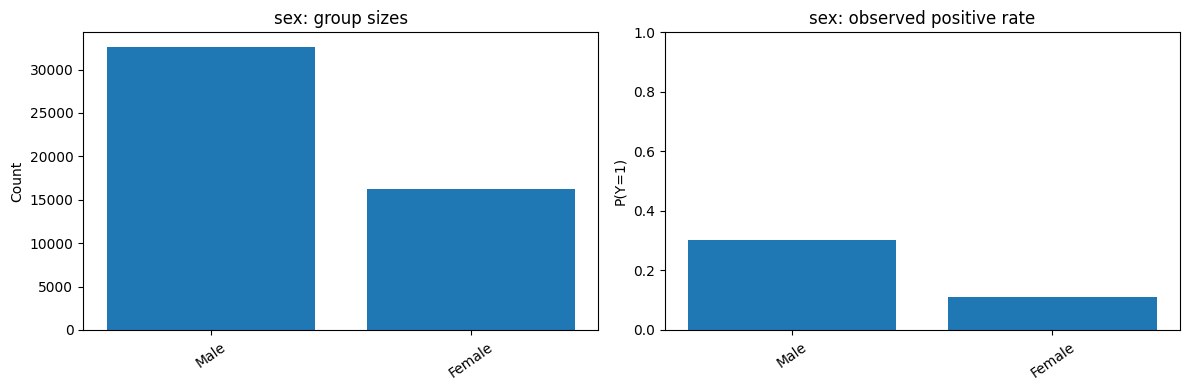


Sensitive attribute: race


,group,n,positive_rate,share
4,White,41762,0.253987,0.855043
2,Black,4685,0.120811,0.095922
1,Asian-Pac-Islander,1519,0.269256,0.031100
0,Amer-Indian-Eskimo,470,0.117021,0.009623
3,Other,406,0.123153,0.008313


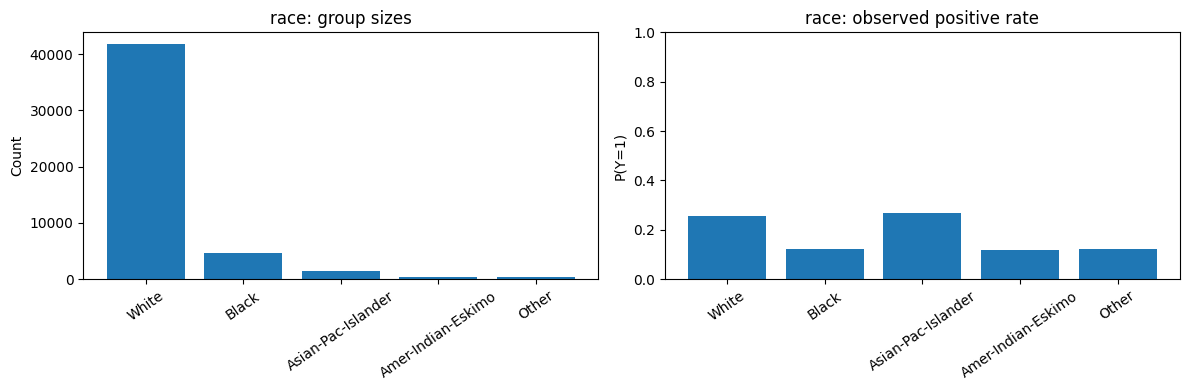

In [ ]:
def sensitive_summary(X_data: pd.DataFrame, y_data: pd.Series, attribute: str) -> pd.DataFrame:
    # Combine the selected sensitive attribute with the target labels for group-level analysis.
    table = (
        pd.DataFrame({
            "group": X_data[attribute].astype(str),
            "target": y_data.to_numpy(),
        })
        # Calculate the sample count and observed positive-label rate for each group.
        .groupby("group", dropna=False)
        .agg(n=("target", "size"), positive_rate=("target", "mean"))
        .reset_index()
        .sort_values("n", ascending=False)
    )
    # Calculate each group's proportion of the complete dataset.
    table["share"] = table["n"] / table["n"].sum()
    return table


# Store the composition summary generated for every sensitive attribute.
DATASET_COMPOSITION_TABLES = {}
for attribute in SENSITIVE_ATTRIBUTES:
    # Generate and persist the tabular composition summary for the current attribute.
    table = sensitive_summary(X, y, attribute)
    DATASET_COMPOSITION_TABLES[attribute] = table
    table.to_csv(RESULTS_ROOT / f"{attribute}_dataset_composition.csv", index=False)

    print(f"\nSensitive attribute: {attribute}")
    display(table)

    # Plot group sizes and observed positive rates side by side.
    figure, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].bar(table["group"], table["n"])
    axes[0].set_title(f"{attribute}: group sizes")
    axes[0].set_ylabel("Count")
    axes[0].tick_params(axis="x", rotation=35)

    axes[1].bar(table["group"], table["positive_rate"])
    axes[1].set_title(f"{attribute}: observed positive rate")
    axes[1].set_ylabel("P(Y=1)")
    axes[1].set_ylim(0, 1)
    axes[1].tick_params(axis="x", rotation=35)

    # Finalize, save, display, and release the composition figure.
    figure.tight_layout()
    figure.savefig(
        RESULTS_ROOT / f"{attribute}_dataset_composition.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(figure)

## Train, validation, and test split

In [5]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
X_train, X_validation, y_train, y_validation = train_test_split(
    X_train_full, y_train_full, test_size=0.20, random_state=SEED, stratify=y_train_full
)
for frame in (X_train, X_validation, X_test):
    frame.reset_index(drop=True, inplace=True)
for series in (y_train, y_validation, y_test):
    series.reset_index(drop=True, inplace=True)

print("Train:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)

Train: (31258, 14)
Validation: (7815, 14)
Test: (9769, 14)


## Preprocessing and model definitions

In [ ]:
def make_one_hot_encoder() -> OneHotEncoder:
    # Use the current scikit-learn argument when available.
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    # Fall back to the legacy argument for older scikit-learn versions.
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)


def build_preprocessor(feature_frame: pd.DataFrame):
    # Separate numeric and categorical columns for type-specific preprocessing.
    numeric_columns = feature_frame.select_dtypes(include=["number"]).columns.tolist()
    categorical_columns = [column for column in feature_frame.columns if column not in numeric_columns]

    # Impute missing numeric values and standardize their scales.
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    # Impute missing categorical values and convert categories to one-hot features.
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", make_one_hot_encoder()),
    ])

    # Apply each preprocessing pipeline only to its corresponding column group.
    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ])
    return preprocessor, numeric_columns, categorical_columns


def build_model_pipeline(feature_frame: pd.DataFrame, model_name: str) -> Pipeline:
    # Build a fresh preprocessor for the provided feature schema.
    preprocessor, _, _ = build_preprocessor(feature_frame)

    # Configure the requested estimator with reproducible settings.
    if model_name == "Logistic Regression":
        estimator = LogisticRegression(
            max_iter=2000,
            solver="lbfgs",
            random_state=SEED,
        )
    elif model_name == "Random Forest":
        estimator = RandomForestClassifier(
            n_estimators=CONFIG["rf_estimators"],
            min_samples_leaf=2,
            max_features="sqrt",
            n_jobs=-1,
            random_state=SEED,
        )
    else:
        raise ValueError(f"Unsupported model: {model_name}")

    # Ensure identical preprocessing is applied during fitting and prediction.
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", estimator),
    ])


# Define the model families evaluated in the experiment.
MODEL_NAMES = ["Logistic Regression", "Random Forest"]
# Extract and retain the feature-type assignments used by the preprocessor.
_, NUMERIC_COLUMNS, CATEGORICAL_COLUMNS = build_preprocessor(X_train)

print("Numeric columns:", NUMERIC_COLUMNS)
print("Categorical columns:", CATEGORICAL_COLUMNS)
print(
    "Methodological note: Adult contains both 'education' and 'education-num', which encode "
    "the same educational level in two forms. Both are retained to preserve the original "
    "experiment, but counterfactual generation will always change them together."
)
print(
    "Methodological note: 'fnlwgt' is a census sampling weight. Its inclusion as a predictor "
    "must be acknowledged when interpreting the model."
)

Numeric columns: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']
Categorical columns: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Methodological note: Adult contains both 'education' and 'education-num', which encode the same educational level in two forms. Both are retained to preserve the original experiment, but counterfactual generation will always change them together.
Methodological note: 'fnlwgt' is a census sampling weight. Its inclusion as a predictor must be acknowledged when interpreting the model.


## Train both models and report standard metrics

In [ ]:
def predictive_metrics(
    y_true: pd.Series | np.ndarray,
    probabilities: np.ndarray,
    predictions: Optional[np.ndarray] = None,
    threshold: float = 0.5,
) -> dict[str, float]:
    # Convert labels and probability scores into consistent NumPy representations.
    y_array = np.asarray(y_true).astype(int)
    probability_array = np.asarray(probabilities).astype(float)
    # Derive binary predictions from the supplied threshold when none are provided.
    if predictions is None:
        predictions = (probability_array >= threshold).astype(int)
    prediction_array = np.asarray(predictions).astype(int)

    # Compute classification, ranking, and probability-calibration metrics.
    return {
        "accuracy": accuracy_score(y_array, prediction_array),
        "precision": precision_score(y_array, prediction_array, zero_division=0),
        "recall": recall_score(y_array, prediction_array, zero_division=0),
        "f1": f1_score(y_array, prediction_array, zero_division=0),
        "roc_auc": roc_auc_score(y_array, probability_array),
        "brier_score": brier_score_loss(y_array, probability_array),
    }


# Store trained pipelines and their test-set outputs for later analyses.
FITTED_MODELS: dict[str, Pipeline] = {}
MODEL_OUTPUTS: dict[str, dict[str, Any]] = {}
performance_records = []

# Train and evaluate every configured model using the same train/test split.
for model_name in MODEL_NAMES:
    print(f"\nTraining {model_name}...")
    pipeline = build_model_pipeline(X_train, model_name)

    # Measure the complete pipeline fitting time.
    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    training_seconds = time.perf_counter() - start

    # Obtain positive-class probabilities and fixed-threshold predictions.
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    # Retain fitted models and raw outputs for downstream fairness analyses.
    FITTED_MODELS[model_name] = pipeline
    MODEL_OUTPUTS[model_name] = {
        "probabilities": probabilities,
        "predictions": predictions,
        "training_seconds": training_seconds,
    }
    # Add the model's predictive metrics and training cost to the summary records.
    performance_records.append({
        "model": model_name,
        **predictive_metrics(y_test, probabilities, predictions),
        "training_seconds": training_seconds,
    })

# Persist and display the consolidated model-performance table.
performance_table = pd.DataFrame(performance_records)
performance_table.to_csv(RESULTS_ROOT / "model_performance.csv", index=False)
display(performance_table)


Training Logistic Regression...

Training Random Forest...


,model,accuracy,precision,recall,f1,roc_auc,brier_score,training_seconds
0,Logistic Regression,0.851264,0.730589,0.599658,0.658680,0.903488,0.103535,1.470388
1,Random Forest,0.866926,0.779333,0.619333,0.690181,0.917019,0.095234,1.807682


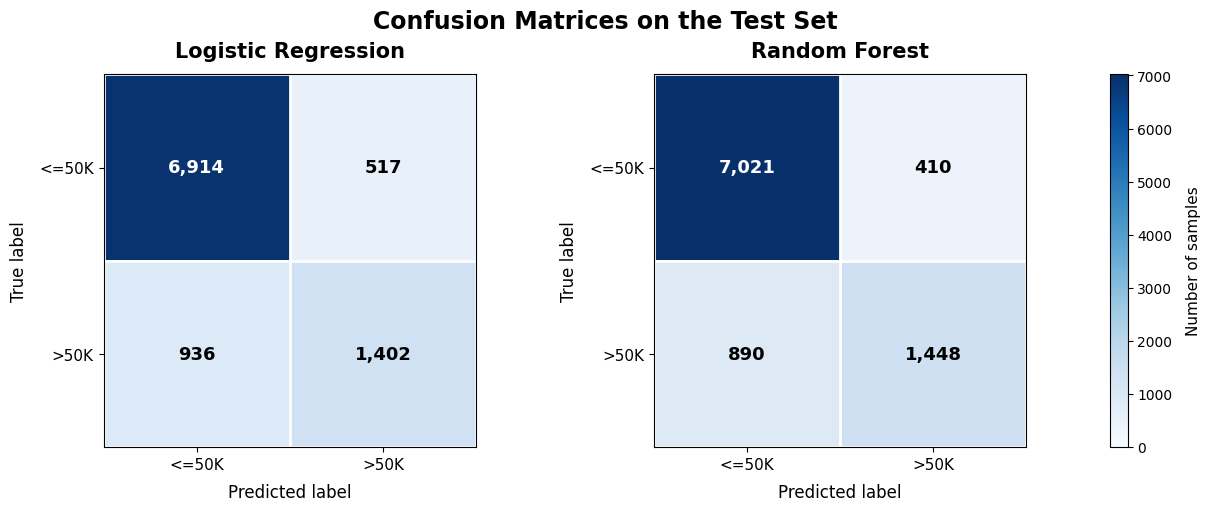

In [8]:
# Compute all confusion matrices first so both plots use the same color scale.
confusion_matrices = {
    model_name: confusion_matrix(
        y_test,
        MODEL_OUTPUTS[model_name]["predictions"],
        labels=[0, 1],
    )
    for model_name in MODEL_NAMES
}

maximum_count = max(
    matrix.max()
    for matrix in confusion_matrices.values()
)

figure = plt.figure(
    figsize=(12, 5),
    constrained_layout=True,
)

grid = figure.add_gridspec(
    nrows=1,
    ncols=3,
    width_ratios=[1, 1, 0.045],
    wspace=0.18,
)

axes = [
    figure.add_subplot(grid[0, 0]),
    figure.add_subplot(grid[0, 1]),
]

colorbar_axis = figure.add_subplot(grid[0, 2])

last_image = None

for axis, model_name in zip(axes, MODEL_NAMES):
    matrix = confusion_matrices[model_name]

    last_image = axis.imshow(
        matrix,
        cmap="Blues",
        vmin=0,
        vmax=maximum_count,
        interpolation="nearest",
        aspect="equal",
    )

    axis.set_title(
        model_name,
        fontsize=15,
        fontweight="bold",
        pad=12,
    )

    axis.set_xlabel(
        "Predicted label",
        fontsize=12,
        labelpad=8,
    )

    axis.set_ylabel(
        "True label",
        fontsize=12,
        labelpad=8,
    )

    axis.set_xticks(
        [0, 1],
        labels=TARGET_LABELS,
    )

    axis.set_yticks(
        [0, 1],
        labels=TARGET_LABELS,
    )

    axis.tick_params(
        axis="both",
        labelsize=11,
    )

    # Use the midpoint of the shared color scale for readable text colors.
    text_threshold = maximum_count / 2.0

    for row in range(matrix.shape[0]):
        for column in range(matrix.shape[1]):
            value = matrix[row, column]

            axis.text(
                column,
                row,
                f"{value:,}",
                ha="center",
                va="center",
                fontsize=13,
                fontweight="bold",
                color=(
                    "white"
                    if value > text_threshold
                    else "black"
                ),
            )

    # Add clear borders between cells.
    axis.set_xticks(
        np.arange(-0.5, matrix.shape[1], 1),
        minor=True,
    )

    axis.set_yticks(
        np.arange(-0.5, matrix.shape[0], 1),
        minor=True,
    )

    axis.grid(
        which="minor",
        color="white",
        linestyle="-",
        linewidth=2,
    )

    axis.tick_params(
        which="minor",
        bottom=False,
        left=False,
    )

colorbar = figure.colorbar(
    last_image,
    cax=colorbar_axis,
)

colorbar.set_label(
    "Number of samples",
    fontsize=11,
    labelpad=10,
)

colorbar.ax.tick_params(
    labelsize=10,
)

figure.suptitle(
    "Confusion Matrices on the Test Set",
    fontsize=17,
    fontweight="bold",
)

figure.savefig(
    RESULTS_ROOT / "confusion_matrices.png",
    dpi=220,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()
plt.close(figure)

## Group fairness and calibration functions

In [ ]:
def safe_ratio(numerator: float, denominator: float) -> float:
    # Return NaN when the ratio is undefined instead of raising a division error.
    return np.nan if denominator == 0 else float(numerator / denominator)


def expected_calibration_error(
    y_true: np.ndarray,
    probabilities: np.ndarray,
    n_bins: int = 10,
) -> float:
    # Convert inputs into consistent numeric NumPy arrays.
    y_array = np.asarray(y_true).astype(int)
    probability_array = np.asarray(probabilities).astype(float)

    # Partition the probability interval into equally spaced calibration bins.
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    bin_ids = np.digitize(probability_array, edges[1:-1], right=True)

    # Accumulate the sample-weighted confidence-versus-outcome gap across non-empty bins.
    ece = 0.0
    for bin_id in range(n_bins):
        mask = bin_ids == bin_id
        if np.any(mask):
            ece += mask.mean() * abs(
                probability_array[mask].mean() - y_array[mask].mean()
            )
    return float(ece)


def adaptive_ece_bins(group_size: int) -> int:
    """Use fewer bins for small groups to avoid nearly empty calibration bins."""
    return int(min(10, max(3, group_size // 50)))


def group_metric_table(
    y_true: pd.Series | np.ndarray,
    probabilities: np.ndarray,
    sensitive_values: pd.Series | np.ndarray,
    predictions: Optional[np.ndarray] = None,
    threshold: float = 0.5,
    min_group_size: int = 1,
) -> pd.DataFrame:
    # Convert labels, probabilities, and sensitive values into aligned NumPy arrays.
    y_array = np.asarray(y_true).astype(int)
    probability_array = np.asarray(probabilities).astype(float)
    sensitive_array = np.asarray(sensitive_values).astype(str)

    # Use supplied predictions or derive them from the probability threshold.
    prediction_array = (
        (probability_array >= threshold).astype(int)
        if predictions is None
        else np.asarray(predictions).astype(int)
    )

    # Compute predictive, fairness, and calibration metrics independently for each group.
    records = []
    for group in sorted(pd.unique(sensitive_array)):
        mask = sensitive_array == group
        group_size = int(mask.sum())
        if group_size < min_group_size:
            continue

        group_y = y_array[mask]
        group_probabilities = probability_array[mask]
        group_predictions = prediction_array[mask]

        # Extract binary confusion-matrix counts in a fixed label order.
        tn, fp, fn, tp = confusion_matrix(
            group_y,
            group_predictions,
            labels=[0, 1],
        ).ravel()

        # Calculate group-level outcome prevalence and calibration settings.
        mean_probability = float(group_probabilities.mean())
        base_rate = float(group_y.mean())
        ece_bins = adaptive_ece_bins(group_size)

        # Store support counts, prediction metrics, error rates, and calibration measures.
        records.append({
            "group": group,
            "n": group_size,
            "n_actual_positive": int(tp + fn),
            "n_actual_negative": int(tn + fp),
            "n_predicted_positive": int(tp + fp),
            "base_rate": base_rate,
            "positive_prediction_rate": float(group_predictions.mean()),
            "accuracy": accuracy_score(group_y, group_predictions),
            "precision": safe_ratio(tp, tp + fp),
            "tpr_recall": safe_ratio(tp, tp + fn),
            "fpr": safe_ratio(fp, fp + tn),
            "fnr": safe_ratio(fn, fn + tp),
            "mean_predicted_probability": mean_probability,
            "calibration_in_the_large": mean_probability - base_rate,
            "calibration_gap": abs(mean_probability - base_rate),
            "brier_score": brier_score_loss(group_y, group_probabilities),
            "ece": expected_calibration_error(
                group_y,
                group_probabilities,
                n_bins=ece_bins,
            ),
            "ece_n_bins": ece_bins,
            # Flag groups whose total, positive, or negative support may be too small.
            "low_support_warning": bool(
                group_size < CONFIG["small_group_warning_threshold"]
                or int(tp + fn) < 20
                or int(tn + fp) < 20
            ),
        })

    return pd.DataFrame(records)


def metric_range(table: pd.DataFrame, column: str) -> float:
    # Compute the max-minus-min gap while ignoring missing or non-numeric values.
    values = pd.to_numeric(table[column], errors="coerce").dropna()
    return np.nan if len(values) < 2 else float(values.max() - values.min())


def finite_max(values: list[float]) -> float:
    # Exclude NaN and infinite values before selecting the maximum.
    finite_values = [float(value) for value in values if np.isfinite(value)]
    return np.nan if not finite_values else max(finite_values)


def fairness_gap_summary(table: pd.DataFrame) -> dict[str, float]:
    # Precompute the TPR and FPR ranges used by multiple fairness criteria.
    tpr_gap = metric_range(table, "tpr_recall")
    fpr_gap = metric_range(table, "fpr")

    # Summarize between-group disparities using max-minus-min ranges.
    return {
        "group_count": int(len(table)),
        "demographic_parity_difference": metric_range(
            table, "positive_prediction_rate"
        ),
        "equal_opportunity_difference": tpr_gap,
        "equalized_odds_difference": finite_max([tpr_gap, fpr_gap]),
        "predictive_parity_difference": metric_range(table, "precision"),
        "fpr_difference": fpr_gap,
        "fnr_difference": metric_range(table, "fnr"),
        "calibration_gap_difference": metric_range(table, "calibration_gap"),
        "brier_score_difference": metric_range(table, "brier_score"),
        "ece_difference": metric_range(table, "ece"),
    }


# Print the disparity convention used throughout the fairness analysis.
print(
    "Fairness-gap convention: for two or more groups, every reported difference is the "
    "max-minus-min range across retained groups. Equalized Odds Difference is the maximum "
    "of the TPR range and FPR range."
)

Fairness-gap convention: for two or more groups, every reported difference is the max-minus-min range across retained groups. Equalized Odds Difference is the maximum of the TPR range and FPR range.


## Fairness analysis for sex, race, and their intersection

In [ ]:
# Store group-level fairness tables by model and sensitive attribute.
FAIRNESS_TABLES: dict[tuple[str, str], pd.DataFrame] = {}
fairness_gap_records = []

# Construct the intersectional sensitive attribute used for combined sex-race analysis.
intersection_test = X_test["sex"].astype(str) + " | " + X_test["race"].astype(str)
attributes = {
    "sex": X_test["sex"],
    "race": X_test["race"],
    "sex_x_race": intersection_test,
}

# Summarize the total and positive-label support of each intersectional group.
intersection_support = (
    pd.DataFrame({"group": intersection_test, "target": y_test.to_numpy()})
    .groupby("group")
    .agg(n=("target", "size"), positive_count=("target", "sum"))
    .reset_index()
    .sort_values("n", ascending=False)
)

# Mark intersectional groups that satisfy the configured minimum sample size.
intersection_support["retained"] = (
    intersection_support["n"] >= CONFIG["minimum_intersection_size"]
)

# Persist and display the intersectional support audit.
intersection_support.to_csv(
    RESULTS_ROOT / "intersection_group_support.csv",
    index=False,
)
print("Intersectional support table:")
display(intersection_support)

# Evaluate group metrics and fairness gaps for every model and sensitive attribute.
for model_name in MODEL_NAMES:
    probabilities = MODEL_OUTPUTS[model_name]["probabilities"]
    predictions = MODEL_OUTPUTS[model_name]["predictions"]

    for attribute_name, sensitive_values in attributes.items():
        # Apply the minimum-support threshold only to intersectional groups.
        minimum_size = (
            CONFIG["minimum_intersection_size"]
            if attribute_name == "sex_x_race"
            else 1
        )

        # Compute group-level predictive, error-rate, and calibration metrics.
        table = group_metric_table(
            y_test,
            probabilities,
            sensitive_values,
            predictions=predictions,
            min_group_size=minimum_size,
        )

        # Retain the detailed table and append its aggregate fairness-gap summary.
        FAIRNESS_TABLES[(model_name, attribute_name)] = table
        fairness_gap_records.append({
            "model": model_name,
            "sensitive_attribute": attribute_name,
            **fairness_gap_summary(table),
        })

        # Save the group-level metrics using a model- and attribute-specific filename.
        table.to_csv(
            RESULTS_ROOT
            / f"{model_name.lower().replace(' ', '_')}_{attribute_name}_group_metrics.csv",
            index=False,
        )

        print(f"\n{model_name} — {attribute_name}")
        display(table)

        # Report groups whose total or class-conditional support may be unreliable.
        if table["low_support_warning"].any():
            affected = table.loc[table["low_support_warning"], "group"].tolist()
            print(
                "Support warning: interpret the following groups cautiously because "
                f"their total or class-conditional sample counts are small: {affected}"
            )

# Consolidate, save, and display fairness gaps across all models and attributes.
fairness_gap_table = pd.DataFrame(fairness_gap_records)
fairness_gap_table.to_csv(RESULTS_ROOT / "fairness_gap_summary.csv", index=False)
display(fairness_gap_table)

Intersectional support table:


,group,n,positive_count,retained
9,Male | White,5699,1804,True
4,Female | White,2649,315,True
7,Male | Black,480,91,True
2,Female | Black,464,30,True
6,Male | Asian-Pac-Islander,190,63,True
1,Female | Asian-Pac-Islander,114,15,True
5,Male | Amer-Indian-Eskimo,62,4,True
8,Male | Other,49,9,True
0,Female | Amer-Indian-Eskimo,42,5,True
3,Female | Other,20,2,False



Logistic Regression — sex


,group,n,n_actual_positive,n_actual_negative,n_predicted_positive,base_rate,positive_prediction_rate,accuracy,precision,tpr_recall,fpr,fnr,mean_predicted_probability,calibration_in_the_large,calibration_gap,brier_score,ece,ece_n_bins,low_support_warning
0,Female,3289,367,2922,236,0.111584,0.071754,0.923685,0.745763,0.479564,0.020534,0.520436,0.107450,-0.004134,0.004134,0.058408,0.012314,10,False
1,Male,6480,1971,4509,1683,0.304167,0.259722,0.814506,0.728461,0.622019,0.101353,0.377981,0.306855,0.002688,0.002688,0.126439,0.009595,10,False



Logistic Regression — race


,group,n,n_actual_positive,n_actual_negative,n_predicted_positive,base_rate,positive_prediction_rate,accuracy,precision,tpr_recall,fpr,fnr,mean_predicted_probability,calibration_in_the_large,calibration_gap,brier_score,ece,ece_n_bins,low_support_warning
0,Amer-Indian-Eskimo,104,9,95,7,0.086538,0.067308,0.942308,0.714286,0.555556,0.021053,0.444444,0.137572,0.051034,0.051034,0.058590,0.067249,3,True
1,Asian-Pac-Islander,304,78,226,82,0.256579,0.269737,0.809211,0.621951,0.653846,0.137168,0.346154,0.283425,0.026846,0.026846,0.127408,0.048471,6,False
2,Black,944,121,823,68,0.128178,0.072034,0.907839,0.750000,0.421488,0.020656,0.578512,0.116217,-0.011961,0.011961,0.065925,0.014494,10,False
3,Other,69,11,58,5,0.159420,0.072464,0.884058,0.800000,0.363636,0.017241,0.636364,0.136524,-0.022897,0.022897,0.081472,0.040746,3,True
4,White,8348,2119,6229,1757,0.253833,0.210470,0.844993,0.734775,0.609250,0.074811,0.390750,0.254220,0.000386,0.000386,0.107660,0.008986,10,False


... (6 outputs left out)

Support warning: interpret the following groups cautiously because their total or class-conditional sample counts are small: [np.str_('Amer-Indian-Eskimo'), np.str_('Other')]

Random Forest — sex_x_race


,group,n,n_actual_positive,n_actual_negative,n_predicted_positive,base_rate,positive_prediction_rate,accuracy,precision,tpr_recall,fpr,fnr,mean_predicted_probability,calibration_in_the_large,calibration_gap,brier_score,ece,ece_n_bins,low_support_warning
0,Female | Amer-Indian-Eskimo,42,5,37,3,0.119048,0.071429,0.904762,0.666667,0.400000,0.027027,0.600000,0.098497,-0.020550,0.020550,0.059152,0.022517,3,True
1,Female | Asian-Pac-Islander,114,15,99,9,0.131579,0.078947,0.894737,0.666667,0.400000,0.030303,0.600000,0.140172,0.008593,0.008593,0.078159,0.029136,3,True
2,Female | Black,464,30,434,20,0.064655,0.043103,0.961207,0.800000,0.533333,0.009217,0.466667,0.069200,0.004545,0.004545,0.034841,0.032545,9,False
3,Female | White,2649,315,2334,212,0.118913,0.080030,0.926387,0.783019,0.526984,0.019709,0.473016,0.116694,-0.002219,0.002219,0.055530,0.011943,10,False
4,Male | Amer-Indian-Eskimo,62,4,58,5,0.064516,0.080645,0.951613,0.600000,0.750000,0.034483,0.250000,0.197796,0.133280,0.133280,0.069823,0.145864,3,True
5,Male | Asian-Pac-Islander,190,63,127,65,0.331579,0.342105,0.800000,0.692308,0.714286,0.157480,0.285714,0.353970,0.022391,0.022391,0.127002,0.045877,3,True
6,Male | Black,480,91,389,58,0.189583,0.120833,0.885417,0.810345,0.516484,0.028278,0.483516,0.181521,-0.008063,0.008063,0.085902,0.031607,9,False
7,Male | Other,49,9,40,4,0.183673,0.081633,0.897959,1.000000,0.444444,0.000000,0.555556,0.167303,-0.016371,0.016371,0.080021,0.016371,3,True
8,Male | White,5699,1804,3895,1480,0.316547,0.259695,0.830146,0.782432,0.641907,0.082670,0.358093,0.317215,0.000669,0.000669,0.119463,0.022485,10,False


Support warning: interpret the following groups cautiously because their total or class-conditional sample counts are small: [np.str_('Female | Amer-Indian-Eskimo'), np.str_('Female | Asian-Pac-Islander'), np.str_('Male | Amer-Indian-Eskimo'), np.str_('Male | Asian-Pac-Islander'), np.str_('Male | Other')]


,model,sensitive_attribute,group_count,demographic_parity_difference,equal_opportunity_difference,equalized_odds_difference,predictive_parity_difference,fpr_difference,fnr_difference,calibration_gap_difference,brier_score_difference,ece_difference
0,Logistic Regression,sex,2,0.187968,0.142455,0.142455,0.017302,0.080819,0.142455,0.001446,0.068032,0.002719
1,Logistic Regression,race,5,0.202429,0.290210,0.290210,0.178049,0.119927,0.290210,0.050647,0.068818,0.058263
2,Logistic Regression,sex_x_race,9,0.339201,0.416667,0.416667,0.454545,0.204724,0.416667,0.105886,0.114008,0.116062
3,Random Forest,sex,2,0.173971,0.117311,0.117311,0.003354,0.059909,0.117311,0.000837,0.062941,0.011331
4,Random Forest,race,5,0.166498,0.199301,0.199301,0.208333,0.084529,0.199301,0.070909,0.047882,0.068651
5,Random Forest,sex_x_race,9,0.299002,0.350000,0.350000,0.400000,0.157480,0.350000,0.132611,0.092161,0.133922


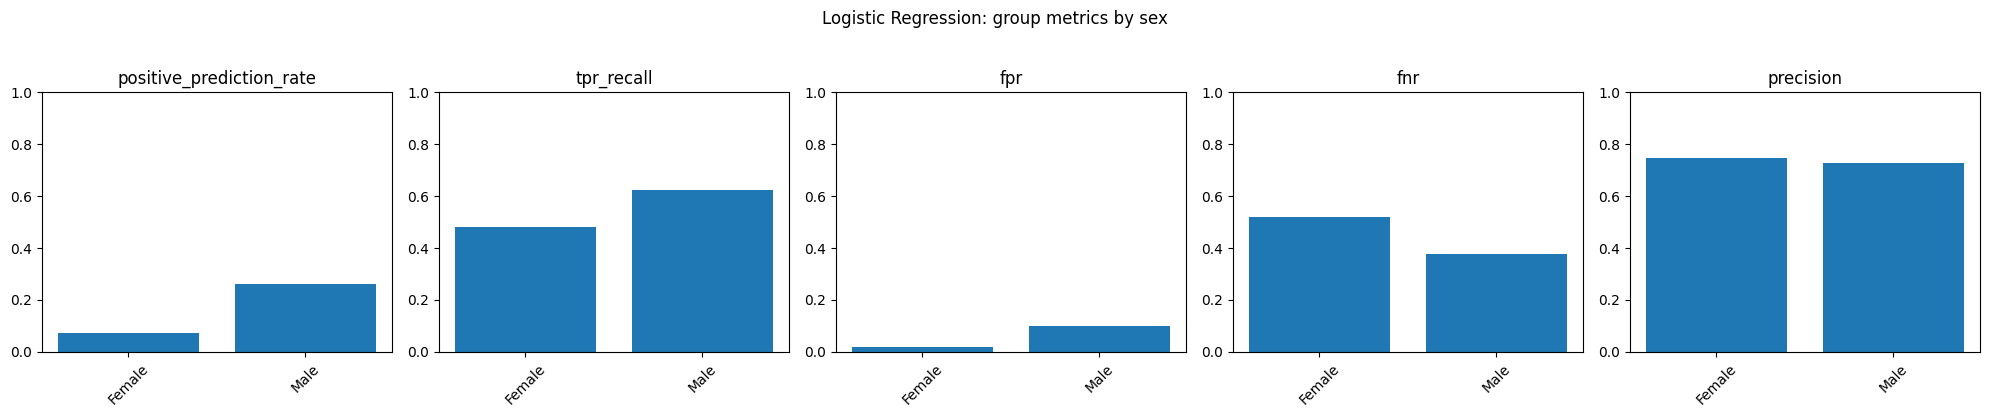

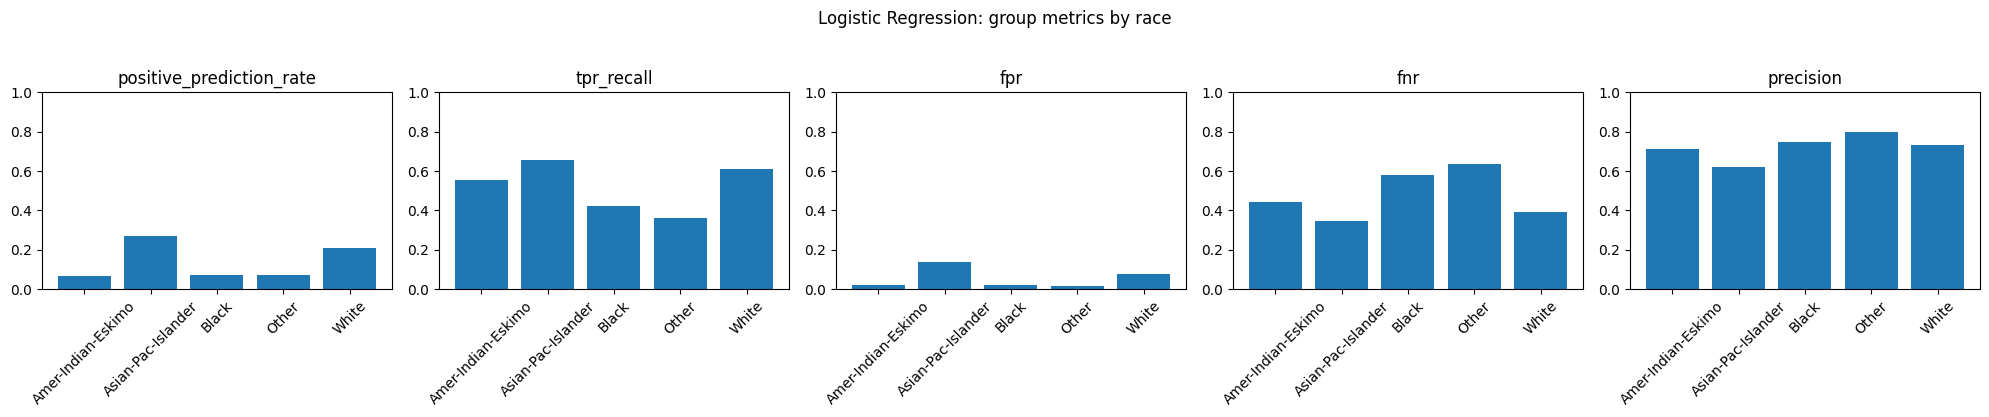

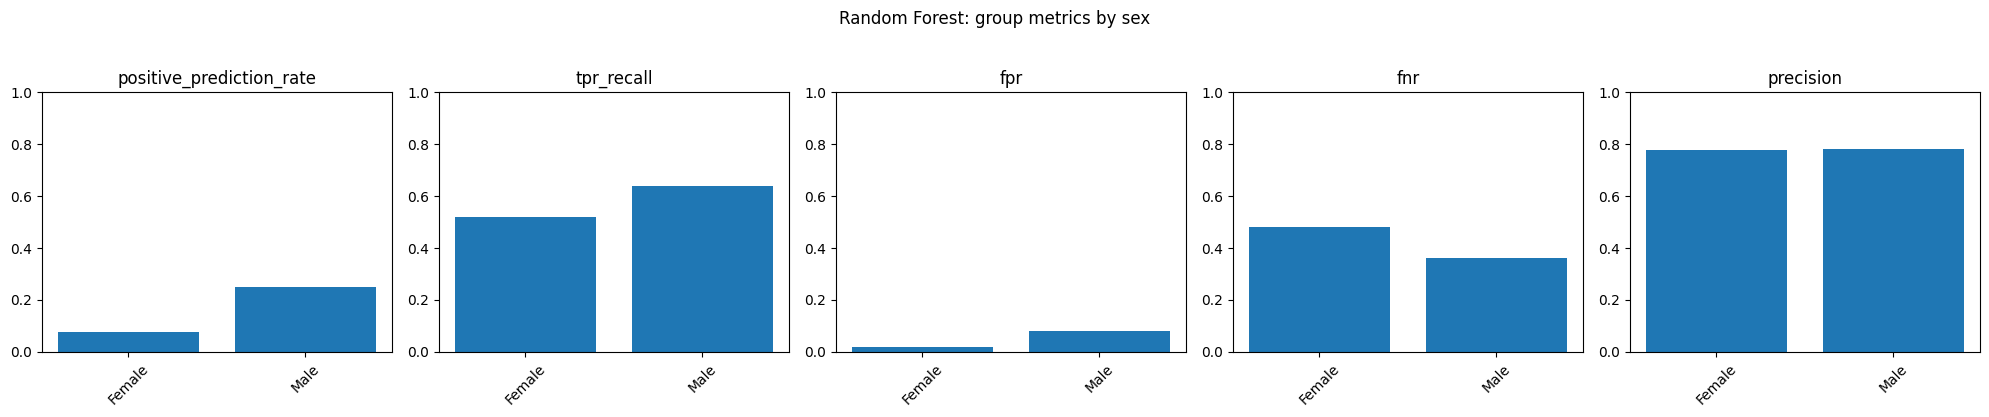

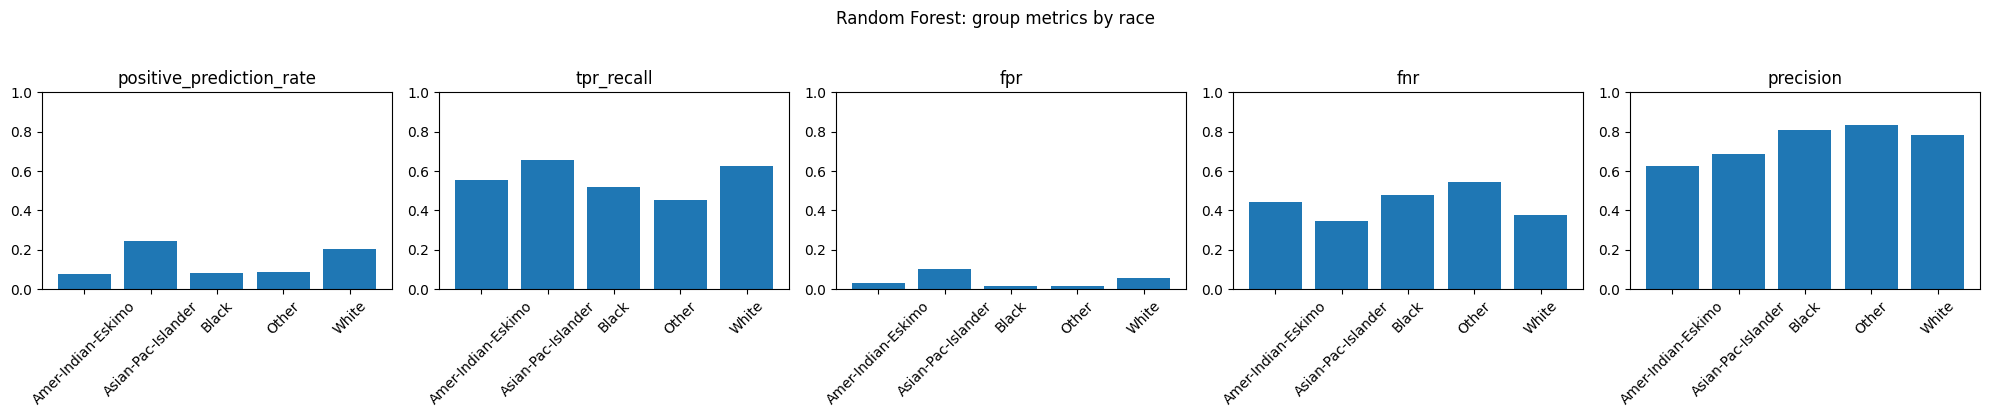

In [11]:
for model_name in MODEL_NAMES:
    for attribute_name in ["sex", "race"]:
        table = FAIRNESS_TABLES[(model_name, attribute_name)]
        metrics = ["positive_prediction_rate", "tpr_recall", "fpr", "fnr", "precision"]
        figure, axes = plt.subplots(1, len(metrics), figsize=(20, 4))
        for axis, metric in zip(axes, metrics):
            axis.bar(table["group"], table[metric])
            axis.set_title(metric); axis.set_ylim(0, 1); axis.tick_params(axis="x", rotation=45)
        figure.suptitle(f"{model_name}: group metrics by {attribute_name}", y=1.03)
        plt.tight_layout()
        plt.savefig(
            RESULTS_ROOT / f"{model_name.lower().replace(' ', '_')}_{attribute_name}_fairness_metrics.png",
            dpi=180, bbox_inches="tight",
        )
        plt.show(); plt.close(figure)

## Identify the more harmed group and discuss error costs

In [ ]:
# Define the relative contribution of each burden component to the descriptive score.
HARM_SCORE_WEIGHTS = {
    "false_negative_burden": 0.60,
    "selection_shortfall": 0.25,
    "calibration_burden": 0.15,
}


def identify_harmed_group(
    table: pd.DataFrame,
    weights: Optional[dict[str, float]] = None,
    return_ranking: bool = False,
):
    """Rank groups with a transparent, context-specific opportunity-burden score.

    This is not a standard fairness metric. It is retained only as a descriptive aid for
    an opportunity-allocation context.
    """
    # Use the default component weights unless an alternative set is supplied.
    selected_weights = HARM_SCORE_WEIGHTS if weights is None else weights
    required_weights = {
        "false_negative_burden",
        "selection_shortfall",
        "calibration_burden",
    }
    # Require exactly the expected components so the score remains interpretable.
    if set(selected_weights) != required_weights:
        raise ValueError(f"Weights must contain exactly: {sorted(required_weights)}")

    # Normalize weights so their relative values determine a unit-sum combination.
    weight_sum = float(sum(selected_weights.values()))
    if weight_sum <= 0:
        raise ValueError("Harm-score weights must sum to a positive value.")
    normalized_weights = {
        key: float(value) / weight_sum for key, value in selected_weights.items()
    }

    # Create a working copy so the original group-metric table is not modified.
    ranked = table.copy()
    ranked["false_negative_burden"] = pd.to_numeric(
        ranked["fnr"], errors="coerce"
    )

    # Measure each group's selection-rate shortfall relative to the highest-rate group.
    maximum_positive_rate = pd.to_numeric(
        ranked["positive_prediction_rate"], errors="coerce"
    ).max()
    ranked["selection_shortfall"] = (
        maximum_positive_rate
        - pd.to_numeric(ranked["positive_prediction_rate"], errors="coerce")
    )

    # Use the absolute group calibration gap as the calibration-burden component.
    ranked["calibration_burden"] = pd.to_numeric(
        ranked["calibration_gap"], errors="coerce"
    )

    # Mark rows for which every required score component is available.
    components = [
        "false_negative_burden",
        "selection_shortfall",
        "calibration_burden",
    ]
    ranked["harm_score_valid"] = ranked[components].notna().all(axis=1)

    # Combine the three burden components using the normalized weights.
    ranked["harm_score"] = (
        normalized_weights["false_negative_burden"]
        * ranked["false_negative_burden"]
        + normalized_weights["selection_shortfall"]
        * ranked["selection_shortfall"]
        + normalized_weights["calibration_burden"]
        * ranked["calibration_burden"]
    )

    # Rank valid groups by harm score, using FNR as a deterministic tie-breaker.
    valid_ranking = ranked.loc[ranked["harm_score_valid"]].sort_values(
        ["harm_score", "fnr"],
        ascending=[False, False],
    )
    if valid_ranking.empty:
        raise ValueError("No group has all components required for harm_score.")

    # Select the group with the largest context-specific opportunity burden.
    harmed_group = valid_ranking.iloc[0]
    if return_ranking:
        return harmed_group, ranked.sort_values("harm_score", ascending=False)
    return harmed_group


# State the score definition and its limited interpretive role.
print(
    "harm_score = 0.60 × FNR + 0.25 × selection shortfall + "
    "0.15 × absolute calibration gap."
)
print(
    "This score is a context-specific descriptive aid, not a replacement for reporting "
    "the separate fairness metrics."
)

# Compute and save the sex-group harm ranking for every fitted model.
HARM_RANKINGS = {}
for model_name in MODEL_NAMES:
    harmed, ranking = identify_harmed_group(
        FAIRNESS_TABLES[(model_name, "sex")],
        return_ranking=True,
    )
    HARM_RANKINGS[model_name] = ranking
    ranking.to_csv(
        RESULTS_ROOT / f"{model_name.lower().replace(' ', '_')}_sex_harm_ranking.csv",
        index=False,
    )

    # Report the leading group together with the components driving its score.
    print(
        f"{model_name}: the largest context-specific opportunity burden appears for "
        f"'{harmed['group']}' (harm_score={harmed['harm_score']:.3f}, "
        f"FNR={harmed['fnr']:.3f}, selection shortfall="
        f"{harmed['selection_shortfall']:.3f}, calibration gap="
        f"{harmed['calibration_gap']:.3f})."
    )

# Clarify that the relative severity of classification errors depends on deployment context.
print(
    "In an opportunity-allocation use case, false negatives can be especially harmful "
    "because qualified people may be denied an opportunity. False positives can impose "
    "institutional or downstream costs. The relative cost remains context dependent."
)

harm_score = 0.60 × FNR + 0.25 × selection shortfall + 0.15 × absolute calibration gap.
This score is a context-specific descriptive aid, not a replacement for reporting the separate fairness metrics.
Logistic Regression: the largest context-specific opportunity burden appears for 'Female' (harm_score=0.360, FNR=0.520, selection shortfall=0.188, calibration gap=0.004).
Random Forest: the largest context-specific opportunity burden appears for 'Female' (harm_score=0.331, FNR=0.480, selection shortfall=0.174, calibration gap=0.001).
In an opportunity-allocation use case, false negatives can be especially harmful because qualified people may be denied an opportunity. False positives can impose institutional or downstream costs. The relative cost remains context dependent.


## Calibration by group

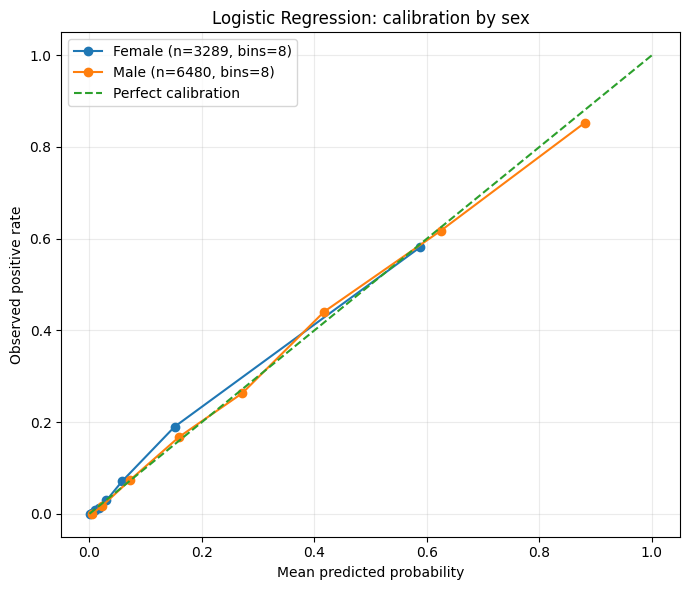

Calibration warning for race='Amer-Indian-Eskimo': n=104; the curve may be noisy and should be interpreted with the tabular Brier/ECE metrics and support counts.
Calibration warning for race='Other': n=69; the curve may be noisy and should be interpreted with the tabular Brier/ECE metrics and support counts.


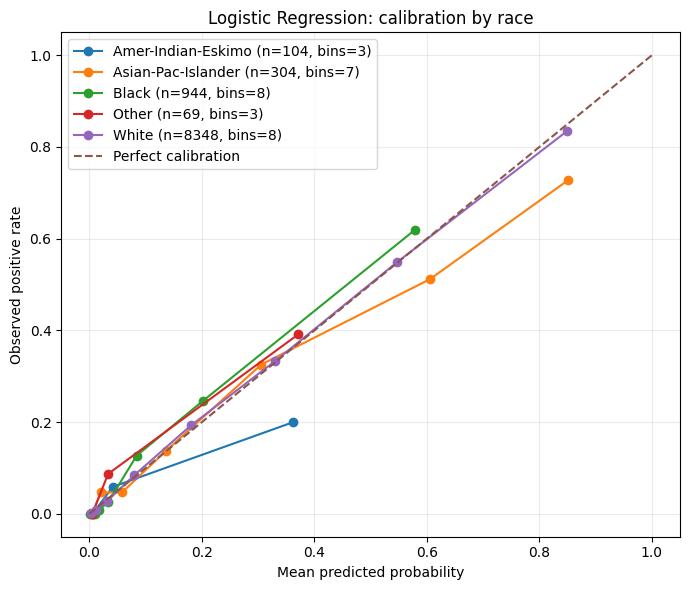

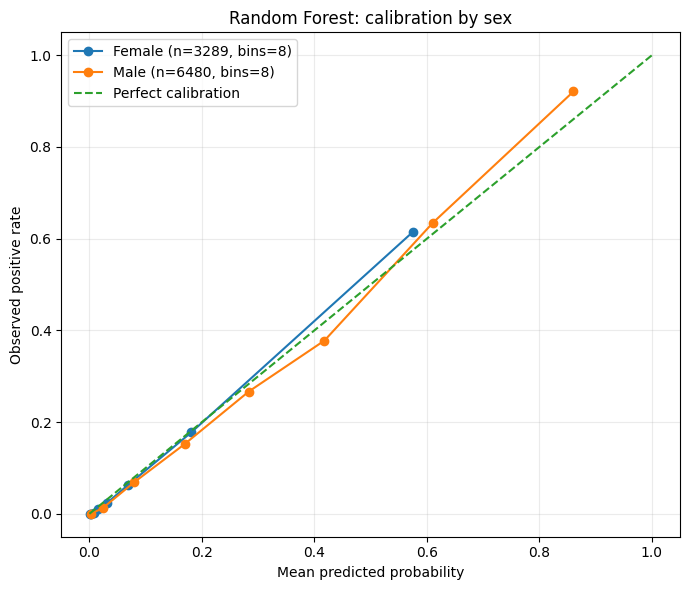

Calibration warning for race='Amer-Indian-Eskimo': n=104; the curve may be noisy and should be interpreted with the tabular Brier/ECE metrics and support counts.
Calibration warning for race='Other': n=69; the curve may be noisy and should be interpreted with the tabular Brier/ECE metrics and support counts.


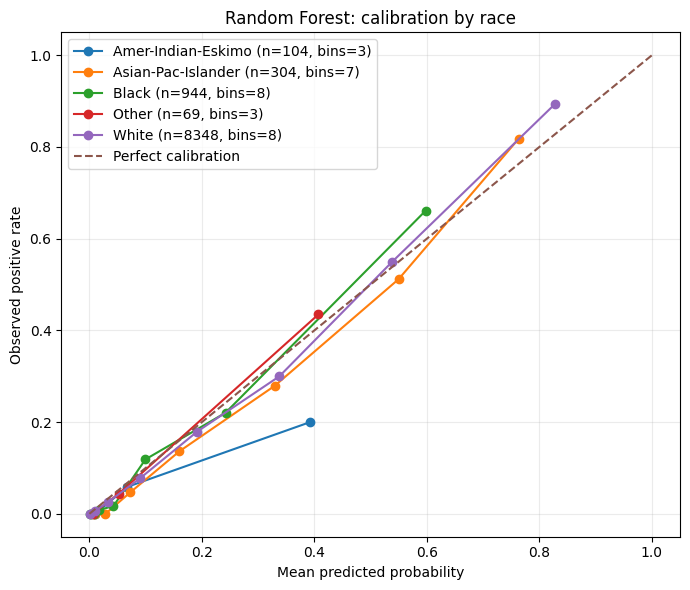

In [ ]:
def calibration_bin_count(group_size: int, requested_bins: int = 8) -> int:
    """Choose a conservative number of quantile bins for each group."""
    # Limit the number of bins for smaller groups while retaining at least three.
    return int(min(requested_bins, max(3, group_size // 40)))


def plot_group_calibration(
    model_name: str,
    attribute: str,
    sensitive_values: pd.Series,
    requested_bins: int = 8,
    minimum_group_size: Optional[int] = None,
) -> pd.DataFrame:
    # Retrieve the model probabilities and align labels and group values as arrays.
    probabilities = MODEL_OUTPUTS[model_name]["probabilities"]
    y_array = y_test.to_numpy()
    sensitive_array = sensitive_values.astype(str).to_numpy()
    # Use the configured minimum support unless an explicit value is provided.
    minimum_size = (
        CONFIG["calibration_min_group_size"]
        if minimum_group_size is None
        else minimum_group_size
    )

    # Store calibration points for all retained groups.
    calibration_records = []
    figure, axis = plt.subplots(figsize=(7, 6))

    # Generate a separate calibration curve for each sensitive group.
    for group in sorted(pd.unique(sensitive_array)):
        mask = sensitive_array == group
        group_size = int(mask.sum())
        # Exclude groups whose sample size is below the required threshold.
        if group_size < minimum_size:
            print(
                f"Skipping {attribute}={group!r} calibration curve: "
                f"n={group_size} < {minimum_size}."
            )
            continue

        # Select a support-aware number of quantile bins for the current group.
        n_bins = calibration_bin_count(group_size, requested_bins)
        fraction_positive, mean_predicted = calibration_curve(
            y_array[mask],
            probabilities[mask],
            n_bins=n_bins,
            strategy="quantile",
        )
        axis.plot(
            mean_predicted,
            fraction_positive,
            marker="o",
            label=f"{group} (n={group_size}, bins={n_bins})",
        )

        # Save every plotted calibration point for later tabular analysis.
        for bin_index, (mean_probability, observed_rate) in enumerate(
            zip(mean_predicted, fraction_positive),
            start=1,
        ):
            calibration_records.append({
                "model": model_name,
                "sensitive_attribute": attribute,
                "group": group,
                "group_n": group_size,
                "n_bins": n_bins,
                "bin_index": bin_index,
                "mean_predicted_probability": float(mean_probability),
                "observed_positive_rate": float(observed_rate),
            })

        # Warn when the retained group may still produce a noisy calibration curve.
        if group_size < CONFIG["small_group_warning_threshold"]:
            print(
                f"Calibration warning for {attribute}={group!r}: n={group_size}; "
                "the curve may be noisy and should be interpreted with the tabular "
                "Brier/ECE metrics and support counts."
            )

    # Add the ideal calibration reference line and finalize the plot.
    axis.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
    axis.set_xlabel("Mean predicted probability")
    axis.set_ylabel("Observed positive rate")
    axis.set_title(f"{model_name}: calibration by {attribute}")
    axis.legend()
    axis.grid(alpha=0.25)
    figure.tight_layout()
    figure.savefig(
        RESULTS_ROOT
        / f"{model_name.lower().replace(' ', '_')}_{attribute}_calibration.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(figure)

    # Persist the calibration points used to construct the group curves.
    calibration_table = pd.DataFrame(calibration_records)
    calibration_table.to_csv(
        RESULTS_ROOT
        / f"{model_name.lower().replace(' ', '_')}_{attribute}_calibration_points.csv",
        index=False,
    )
    return calibration_table


# Generate and retain sex- and race-specific calibration tables for every model.
CALIBRATION_POINT_TABLES = {}
for model_name in MODEL_NAMES:
    CALIBRATION_POINT_TABLES[(model_name, "sex")] = plot_group_calibration(
        model_name, "sex", X_test["sex"]
    )
    CALIBRATION_POINT_TABLES[(model_name, "race")] = plot_group_calibration(
        model_name, "race", X_test["race"]
    )

## Sensitive-feature removal and proxy analysis

In [ ]:
# Define the explicit sensitive attributes removed in this comparison.
DROP_SENSITIVE = ["sex", "race"]

# Create train and test feature sets without the selected sensitive columns.
X_train_no_sensitive = X_train.drop(columns=DROP_SENSITIVE)
X_test_no_sensitive = X_test.drop(columns=DROP_SENSITIVE)

# Build a Random Forest pipeline using only the remaining features.
rf_without_sensitive = build_model_pipeline(
    X_train_no_sensitive,
    "Random Forest",
)

# Fit the reduced-feature model and record its training time.
start = time.perf_counter()
rf_without_sensitive.fit(X_train_no_sensitive, y_train)
no_sensitive_training_seconds = time.perf_counter() - start

# Generate positive-class probabilities and fixed-threshold predictions.
prob_no_sensitive = rf_without_sensitive.predict_proba(X_test_no_sensitive)[:, 1]
pred_no_sensitive = (prob_no_sensitive >= 0.5).astype(int)

# Compare predictive performance with and without the explicit sensitive features.
sensitive_removal_comparison = pd.DataFrame([
    {
        "model": "Random Forest with sensitive features",
        **predictive_metrics(
            y_test,
            MODEL_OUTPUTS["Random Forest"]["probabilities"],
            MODEL_OUTPUTS["Random Forest"]["predictions"],
        ),
        "training_seconds": MODEL_OUTPUTS["Random Forest"]["training_seconds"],
    },
    {
        "model": "Random Forest without sex and race",
        **predictive_metrics(y_test, prob_no_sensitive, pred_no_sensitive),
        "training_seconds": no_sensitive_training_seconds,
    },
])

# Persist and display the predictive-performance comparison.
sensitive_removal_comparison.to_csv(
    RESULTS_ROOT / "sensitive_feature_removal_performance.csv",
    index=False,
)
display(sensitive_removal_comparison)

# Store group-level tables and aggregate fairness gaps for the reduced-feature model.
sensitive_removal_gap_records = []
SENSITIVE_REMOVAL_GROUP_TABLES = {}

# Evaluate fairness separately for every configured sensitive attribute.
for attribute in SENSITIVE_ATTRIBUTES:
    print(f"\nWithout sensitive features — fairness by {attribute}")

    # Compute group-level metrics using the original sensitive values only for auditing.
    table = group_metric_table(
        y_test,
        prob_no_sensitive,
        X_test[attribute],
        predictions=pred_no_sensitive,
    )

    # Retain the detailed group table and calculate its fairness-gap summary.
    SENSITIVE_REMOVAL_GROUP_TABLES[attribute] = table
    gaps = fairness_gap_summary(table)
    sensitive_removal_gap_records.append({
        "model": "Random Forest without sex and race",
        "sensitive_attribute": attribute,
        **gaps,
    })

    # Save and display the group-level fairness results.
    table.to_csv(
        RESULTS_ROOT / f"random_forest_without_sensitive_{attribute}_group_metrics.csv",
        index=False,
    )
    display(table)
    print(gaps)

# Consolidate and persist fairness gaps across sensitive attributes.
sensitive_removal_gap_table = pd.DataFrame(sensitive_removal_gap_records)
sensitive_removal_gap_table.to_csv(
    RESULTS_ROOT / "sensitive_feature_removal_fairness.csv",
    index=False,
)

print(
    "Removing explicit sensitive attributes does not guarantee fairness because variables "
    "such as relationship, marital status, occupation, education, and work history may act "
    "as proxy features. The comparison above must therefore be interpreted jointly with "
    "global feature-importance results."
)

,model,accuracy,precision,recall,f1,roc_auc,brier_score,training_seconds
0,Random Forest with sensitive features,0.866926,0.779333,0.619333,0.690181,0.917019,0.095234,1.807682
1,Random Forest without sex and race,0.866619,0.778076,0.619333,0.689688,0.916347,0.095780,1.701065



Without sensitive features — fairness by sex


,group,n,n_actual_positive,n_actual_negative,n_predicted_positive,base_rate,positive_prediction_rate,accuracy,precision,tpr_recall,fpr,fnr,mean_predicted_probability,calibration_in_the_large,calibration_gap,brier_score,ece,ece_n_bins,low_support_warning
0,Female,3289,367,2922,245,0.111584,0.074491,0.930070,0.779592,0.520436,0.018480,0.479564,0.118002,0.006418,0.006418,0.053935,0.019696,10,False
1,Male,6480,1971,4509,1616,0.304167,0.249383,0.834414,0.777847,0.637747,0.079619,0.362253,0.301672,-0.002495,0.002495,0.117018,0.021179,10,False


{'group_count': 2, 'demographic_parity_difference': 0.174891989384743, 'equal_opportunity_difference': 0.11731136907502104, 'equalized_odds_difference': 0.11731136907502104, 'predictive_parity_difference': 0.0017453020812285835, 'fpr_difference': 0.06113804788324333, 'fnr_difference': 0.11731136907502104, 'calibration_gap_difference': 0.003922956509172307, 'brier_score_difference': 0.06308338970079619, 'ece_difference': 0.001483623173841233}

Without sensitive features — fairness by race


,group,n,n_actual_positive,n_actual_negative,n_predicted_positive,base_rate,positive_prediction_rate,accuracy,precision,tpr_recall,fpr,fnr,mean_predicted_probability,calibration_in_the_large,calibration_gap,brier_score,ece,ece_n_bins,low_support_warning
0,Amer-Indian-Eskimo,104,9,95,9,0.086538,0.086538,0.923077,0.555556,0.555556,0.042105,0.444444,0.170607,0.084069,0.084069,0.070228,0.098212,3,True
1,Asian-Pac-Islander,304,78,226,75,0.256579,0.246711,0.838816,0.693333,0.666667,0.101770,0.333333,0.275426,0.018847,0.018847,0.108828,0.030300,6,False
2,Black,944,121,823,82,0.128178,0.086864,0.916314,0.756098,0.512397,0.024301,0.487603,0.139371,0.011193,0.011193,0.061543,0.035028,10,False
3,Other,69,11,58,6,0.159420,0.086957,0.898551,0.833333,0.454545,0.017241,0.545455,0.154925,-0.004495,0.004495,0.078167,0.014857,3,True
4,White,8348,2119,6229,1689,0.253833,0.202324,0.861045,0.783896,0.624823,0.058597,0.375177,0.251463,-0.002370,0.002370,0.099640,0.020649,10,False


{'group_count': 5, 'demographic_parity_difference': 0.16017206477732793, 'equal_opportunity_difference': 0.2121212121212121, 'equalized_odds_difference': 0.2121212121212121, 'predictive_parity_difference': 0.2777777777777778, 'fpr_difference': 0.08452853219407996, 'fnr_difference': 0.2121212121212121, 'calibration_gap_difference': 0.08169868885477014, 'brier_score_difference': 0.047285132672818815, 'ece_difference': 0.0833546935019231}
Removing explicit sensitive attributes does not guarantee fairness because variables such as relationship, marital status, occupation, education, and work history may act as proxy features. The comparison above must therefore be interpreted jointly with global feature-importance results.


## Global explanation method 1 — Permutation Feature Importance

,feature,importance_mean,importance_std
10,capital-gain,0.046458,0.001561
5,marital-status,0.043682,0.002295
7,relationship,0.018443,0.001515
0,age,0.015667,0.001473
4,education-num,0.011768,0.001301
6,occupation,0.010258,0.002100
12,hours-per-week,0.009175,0.000956
11,capital-loss,0.007593,0.000843
9,sex,0.002322,0.000691
1,workclass,0.002298,0.000709


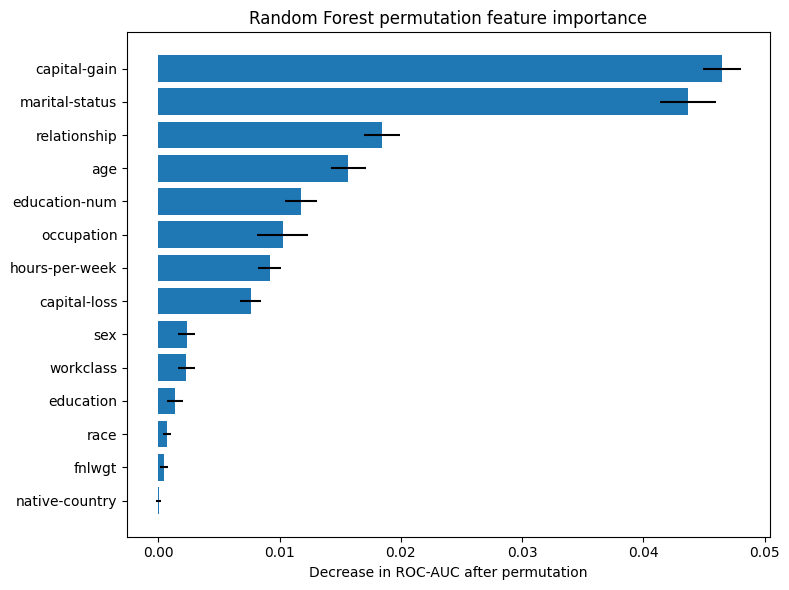

Potential proxy-related top features: ['marital-status', 'relationship', 'education-num', 'occupation', 'hours-per-week', 'workclass', 'education']


In [ ]:
# Select the fitted Random Forest pipeline as the black-box model.
BLACK_BOX_MODEL = FITTED_MODELS["Random Forest"]

# Draw a reproducible subset of the test data for permutation analysis.
permutation_sample = X_test.sample(
    n=min(CONFIG["permutation_samples"], len(X_test)), random_state=SEED
)
# Align the target labels with the sampled feature rows.
permutation_target = y_test.loc[permutation_sample.index]

# Measure each feature's importance through repeated ROC-AUC degradation after permutation.
result = permutation_importance(
    BLACK_BOX_MODEL, permutation_sample, permutation_target,
    scoring="roc_auc", n_repeats=CONFIG["permutation_repeats"],
    random_state=SEED, n_jobs=-1,
)

# Build and rank the feature-importance summary table.
permutation_table = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": result.importances_mean,
    "importance_std": result.importances_std,
}).sort_values("importance_mean", ascending=False)

# Persist and display the highest-ranked permutation importances.
permutation_table.to_csv(RESULTS_ROOT / "permutation_importance.csv", index=False)
display(permutation_table.head(20))

# Plot the fifteen most important features in ascending display order.
top = permutation_table.head(15).sort_values("importance_mean")
figure, axis = plt.subplots(figsize=(8, 6))
axis.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
axis.set_xlabel("Decrease in ROC-AUC after permutation")
axis.set_title("Random Forest permutation feature importance")
plt.tight_layout()
plt.savefig(RESULTS_ROOT / "permutation_importance.png", dpi=180, bbox_inches="tight")
plt.show(); plt.close(figure)

# Identify highly ranked features that may act as proxies for sensitive attributes.
proxy_candidates = {"relationship", "marital-status", "occupation", "education", "education-num", "workclass", "hours-per-week"}
print("Potential proxy-related top features:", [f for f in permutation_table.head(20)["feature"] if f in proxy_candidates])

## Global explanation method 2 — Partial Dependence Plots

PDP features: ['capital-gain', 'age', 'education-num']

PDP feature data types:


capital-gain     float64
age              float64
education-num    float64
dtype: object

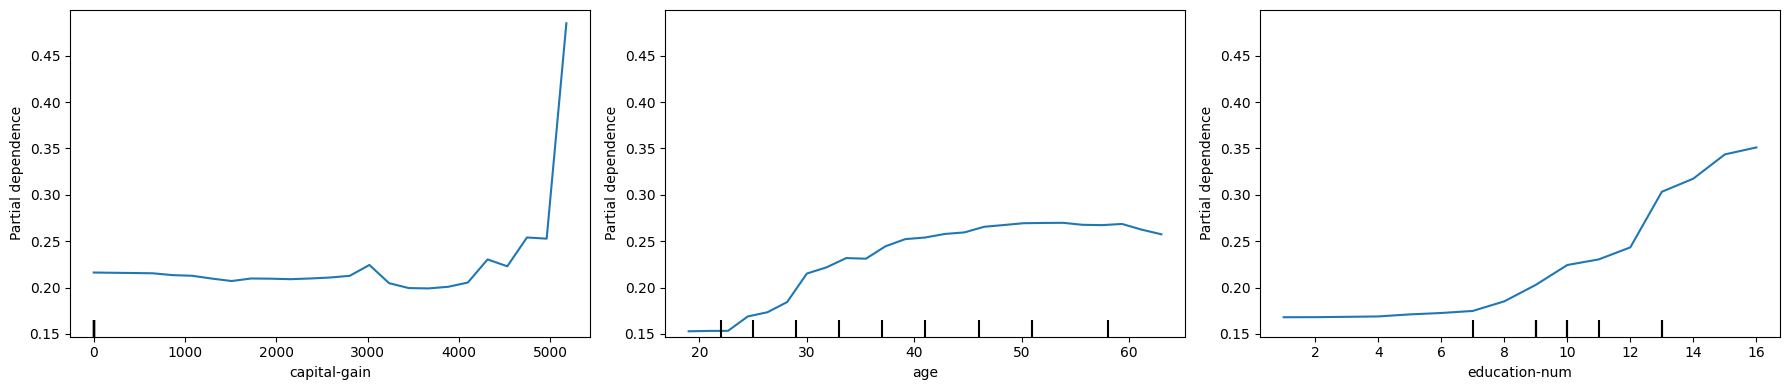

In [ ]:
# Copy the numeric feature list so the original configuration remains unchanged.
numeric_columns = NUMERIC_COLUMNS.copy()

# Select the three highest-ranked numeric features from permutation importance.
top_numeric = [
    feature
    for feature in permutation_table["feature"]
    if feature in numeric_columns
][:3]

# Use predefined numeric features when permutation importance yields too few candidates.
if len(top_numeric) < 2:
    fallback = [
        feature
        for feature in [
            "age",
            "education-num",
            "hours-per-week",
        ]
        if feature in numeric_columns
    ]

    # Preserve feature order while removing duplicates.
    top_numeric = list(
        dict.fromkeys(
            top_numeric + fallback
        )
    )[:3]


# Draw a reproducible test-data subset for partial dependence estimation.
pdp_sample = X_test.sample(
    n=min(
        CONFIG["pdp_samples"],
        len(X_test),
    ),
    random_state=SEED,
).copy()


# PDP creates intermediate floating-point grid values.
# Convert numeric columns to float so Pandas can accept them.
pdp_sample[numeric_columns] = (
    pdp_sample[numeric_columns]
    .astype("float64")
)


# Display the numeric features selected for PDP analysis.
print(
    "PDP features:",
    top_numeric,
)

print(
    "\nPDP feature data types:"
)

# Confirm that the selected PDP features use compatible numeric data types.
display(
    pdp_sample[
        top_numeric
    ].dtypes
)


# Create one plotting axis for each selected numeric feature.
figure, axes = plt.subplots(
    1,
    len(top_numeric),
    figsize=(
        6 * len(top_numeric),
        4,
    ),
)

# Normalize the single-axis case to the iterable format expected below.
if len(top_numeric) == 1:
    axes = [axes]


# Compute and plot average partial dependence for the selected features.
PartialDependenceDisplay.from_estimator(
    BLACK_BOX_MODEL,
    pdp_sample,
    features=top_numeric,
    ax=axes,
    kind="average",
    grid_resolution=25,
)


# Finalize the figure layout before saving.
plt.tight_layout()

# Persist the completed partial dependence plots.
plt.savefig(
    RESULTS_ROOT
    / "partial_dependence_plots.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

## Global explanation method 3 — SHAP summary

/tmp/ipykernel_152724/2457682426.py:111: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


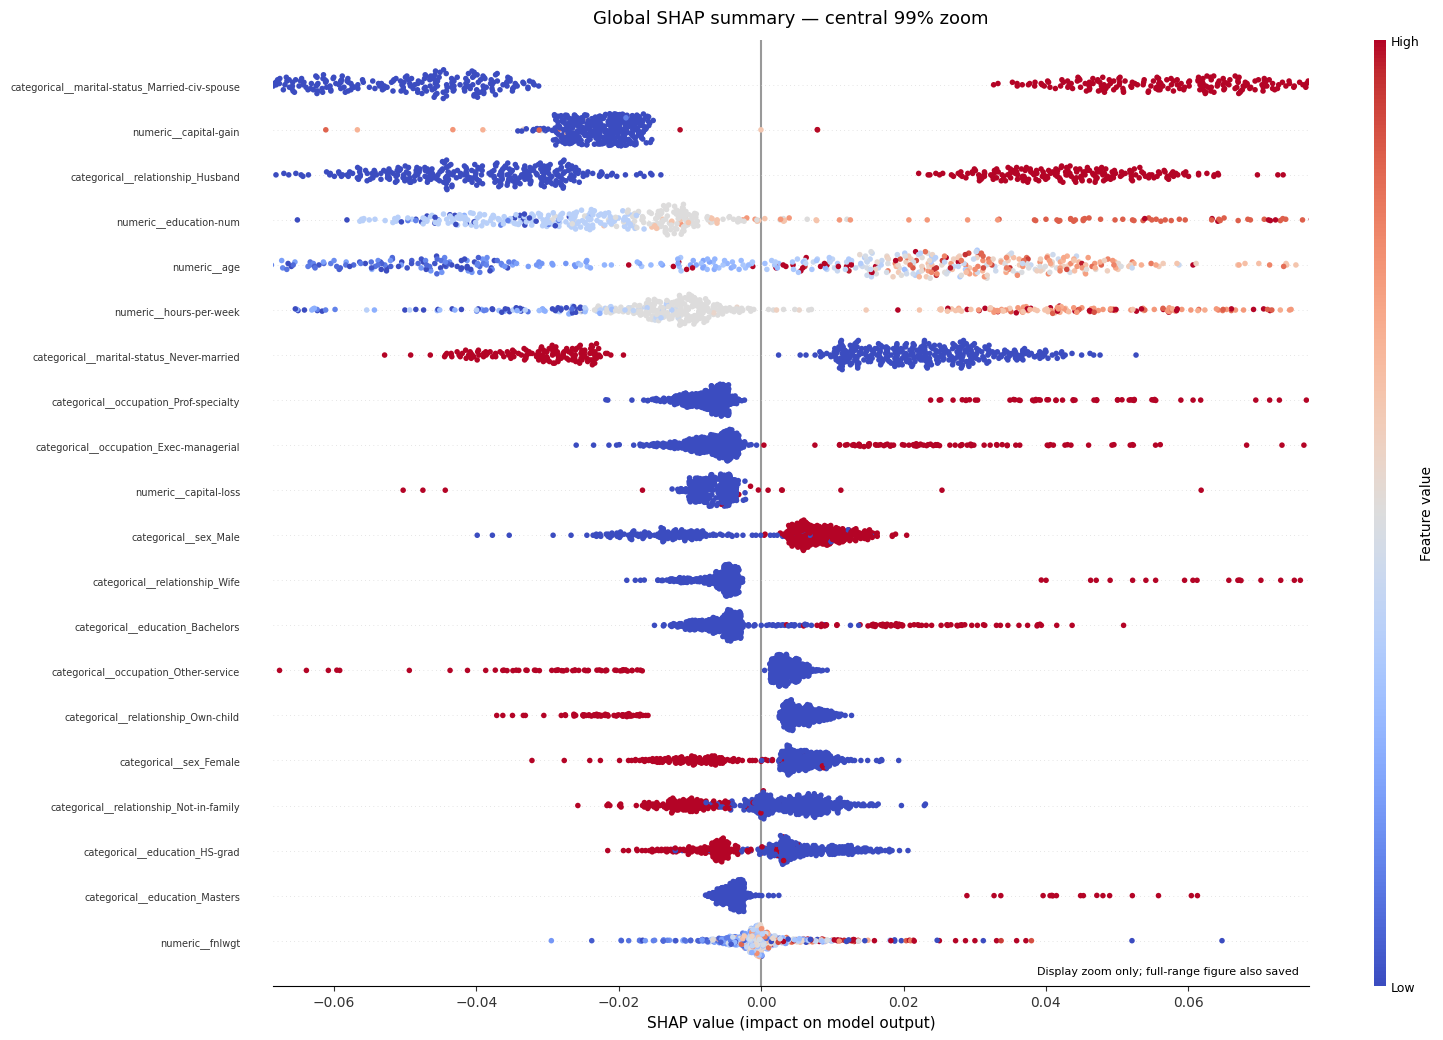

Saved full-range SHAP summary: /mnt/d/AUT/Term 2/TML/Assignments/As3/practical/results_q6_corrected/shap_summary_full_range.png
Saved zoomed SHAP summary: /mnt/d/AUT/Term 2/TML/Assignments/As3/practical/results_q6_corrected/shap_summary_zoomed.png
Saved primary report figure: /mnt/d/AUT/Term 2/TML/Assignments/As3/practical/results_q6_corrected/shap_summary.png
Zoomed SHAP x-axis limits: [-0.0687, 0.0770]


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================
# SHAP global explanation for the black-box Random Forest
# ============================================================

rf_preprocessor = BLACK_BOX_MODEL.named_steps[
    "preprocessor"
]

rf_estimator = BLACK_BOX_MODEL.named_steps[
    "model"
]


# ------------------------------------------------------------
# 1. Select a deterministic sample from the held-out test set
# ------------------------------------------------------------

X_shap_raw = X_test.sample(
    n=min(
        CONFIG["shap_samples"],
        len(X_test),
    ),
    random_state=SEED,
)


# ------------------------------------------------------------
# 2. Apply the already-fitted preprocessing pipeline
# ------------------------------------------------------------

X_shap_transformed = rf_preprocessor.transform(
    X_shap_raw
)

transformed_feature_names = (
    rf_preprocessor.get_feature_names_out()
)


# ------------------------------------------------------------
# 3. Calculate TreeSHAP values
# ------------------------------------------------------------

tree_explainer = shap.TreeExplainer(
    rf_estimator
)

raw_shap_values = tree_explainer.shap_values(
    X_shap_transformed
)


def positive_class_shap(values):
    """
    Return the SHAP values associated with the positive class.

    This supports the common output formats produced by different
    SHAP versions for binary tree classifiers.
    """

    if isinstance(values, list):
        if len(values) < 2:
            raise ValueError(
                "Expected SHAP values for two classes, "
                f"but received {len(values)} list element(s)."
            )

        return np.asarray(
            values[1]
        )

    array = np.asarray(
        values
    )

    # (n_samples, n_features, n_classes)
    if array.ndim == 3:
        if array.shape[2] < 2:
            raise ValueError(
                "Expected a positive-class dimension, "
                f"but received SHAP shape {array.shape}."
            )

        return array[:, :, 1]

    # Some versions directly return:
    # (n_samples, n_features)
    if array.ndim == 2:
        return array

    raise ValueError(
        f"Unexpected SHAP shape: {array.shape}"
    )


shap_values = positive_class_shap(
    raw_shap_values
)


# ------------------------------------------------------------
# 4. Draw the full-range SHAP beeswarm
#
# All 20 features are retained.
# ------------------------------------------------------------

shap.summary_plot(
    shap_values,
    X_shap_transformed,
    feature_names=transformed_feature_names,
    max_display=20,
    cmap=plt.get_cmap("coolwarm"),
    plot_size=(18, 11),
    show=False,
)


figure = plt.gcf()

if not figure.axes:
    raise RuntimeError(
        "SHAP did not create a Matplotlib axis."
    )


# The first axis is the main beeswarm plot.
# The second axis, when present, is the feature-value color bar.
main_axis = figure.axes[0]


# ------------------------------------------------------------
# 5. Improve readability without removing features
# ------------------------------------------------------------

# Reduce only the font size of feature names.
for feature_label in main_axis.get_yticklabels():
    feature_label.set_fontsize(7)

main_axis.tick_params(
    axis="x",
    labelsize=10,
)

main_axis.xaxis.label.set_size(
    11
)

main_axis.set_title(
    "Global SHAP summary — full range",
    fontsize=13,
    pad=12,
)


# Format the color bar.
if len(figure.axes) > 1:
    colorbar_axis = figure.axes[1]

    colorbar_axis.tick_params(
        labelsize=9,
    )

    colorbar_axis.yaxis.label.set_size(
        10
    )


# Allocate less width to the long labels and more to the
# actual SHAP-value distribution.
figure.subplots_adjust(
    left=0.20,
    right=0.92,
    top=0.94,
    bottom=0.08,
)


# ------------------------------------------------------------
# 6. Save the scientifically complete full-range version
# ------------------------------------------------------------

full_range_output_path = (
    RESULTS_ROOT
    / "shap_summary_full_range.png"
)

figure.savefig(
    full_range_output_path,
    dpi=220,
    bbox_inches="tight",
    pad_inches=0.15,
    facecolor="white",
)


# ------------------------------------------------------------
# 7. Calculate readable zoom limits
#
# Only the displayed x-axis is limited. No SHAP values are
# removed from the calculation.
# ------------------------------------------------------------

finite_shap_values = np.asarray(
    shap_values,
    dtype=float,
)

finite_shap_values = finite_shap_values[
    np.isfinite(
        finite_shap_values
    )
]

if finite_shap_values.size == 0:
    raise RuntimeError(
        "No finite SHAP values were available for plotting."
    )


# Keep the central 99% of SHAP values visible.
# This suppresses the visual effect of a few extreme capital-gain
# values while retaining their full-range version in a separate file.
zoom_lower, zoom_upper = np.quantile(
    finite_shap_values,
    [
        0.005,
        0.995,
    ],
)

zoom_span = max(
    float(
        zoom_upper
        - zoom_lower
    ),
    1e-6,
)

zoom_margin = (
    0.08
    * zoom_span
)

zoom_left = min(
    float(
        zoom_lower
        - zoom_margin
    ),
    0.0,
)

zoom_right = max(
    float(
        zoom_upper
        + zoom_margin
    ),
    0.0,
)


main_axis.set_xlim(
    zoom_left,
    zoom_right,
)

main_axis.set_title(
    "Global SHAP summary — central 99% zoom",
    fontsize=13,
    pad=12,
)


# Add a note clarifying that the axis—not the data—was truncated.
main_axis.text(
    0.99,
    0.01,
    "Display zoom only; full-range figure also saved",
    transform=main_axis.transAxes,
    ha="right",
    va="bottom",
    fontsize=8,
)


# ------------------------------------------------------------
# 8. Save the zoomed report-ready version
# ------------------------------------------------------------

zoomed_output_path = (
    RESULTS_ROOT
    / "shap_summary_zoomed.png"
)

figure.savefig(
    zoomed_output_path,
    dpi=220,
    bbox_inches="tight",
    pad_inches=0.15,
    facecolor="white",
)


# Preserve the original expected filename for downstream use.
main_output_path = (
    RESULTS_ROOT
    / "shap_summary.png"
)

figure.savefig(
    main_output_path,
    dpi=220,
    bbox_inches="tight",
    pad_inches=0.15,
    facecolor="white",
)


# The displayed notebook output is the clearer zoomed version.
plt.show()
plt.close(
    figure
)


# ------------------------------------------------------------
# 9. Report saved files and zoom range
# ------------------------------------------------------------

print(
    "Saved full-range SHAP summary:",
    full_range_output_path.resolve(),
)

print(
    "Saved zoomed SHAP summary:",
    zoomed_output_path.resolve(),
)

print(
    "Saved primary report figure:",
    main_output_path.resolve(),
)

print(
    "Zoomed SHAP x-axis limits:",
    f"[{zoom_left:.4f}, {zoom_right:.4f}]",
)

## Local explanations for the three required samples

In [18]:
rf_probabilities = MODEL_OUTPUTS["Random Forest"]["probabilities"]
rf_predictions = MODEL_OUTPUTS["Random Forest"]["predictions"]
selection_frame = X_test.copy()
selection_frame["true_label"] = y_test.to_numpy()
selection_frame["predicted_label"] = rf_predictions
selection_frame["predicted_probability"] = rf_probabilities
selection_frame["correct_prediction"] = (
    selection_frame["true_label"] == selection_frame["predicted_label"]
)
selection_frame["distance_to_threshold"] = abs(
    selection_frame["predicted_probability"] - 0.5
)


def select_case(
    group_value: str,
    predicted_label: int,
    used_indices: set[int],
    prefer_correct: bool = True,
) -> int:
    base_mask = (
        selection_frame["sex"].astype(str).eq(group_value)
        & selection_frame["predicted_label"].eq(predicted_label)
        & ~selection_frame.index.isin(used_indices)
    )
    candidates = selection_frame.loc[base_mask]

    if prefer_correct:
        correct_candidates = candidates.loc[candidates["correct_prediction"]]
        if not correct_candidates.empty:
            candidates = correct_candidates

    if candidates.empty:
        raise RuntimeError(
            f"No real test sample satisfies sex={group_value!r}, "
            f"predicted_label={predicted_label}."
        )

    # Boundary-near cases make local explanations and recourse less arbitrary and more useful.
    return int(candidates["distance_to_threshold"].idxmin())


used: set[int] = set()
requested = [
    ("group_1_positive", "Female", 1),
    ("group_1_negative", "Female", 0),
    ("group_2_negative", "Male", 0),
]
LOCAL_CASES = []
for case_name, group_value, predicted_label in requested:
    index = select_case(group_value, predicted_label, used)
    used.add(index)
    LOCAL_CASES.append({
        "case_name": case_name,
        "index": index,
        "requested_group": group_value,
        "actual_group": str(X_test.loc[index, "sex"]),
        "true_label": int(y_test.loc[index]),
        "predicted_label": int(rf_predictions[index]),
        "predicted_probability": float(rf_probabilities[index]),
        "correct_prediction": bool(y_test.loc[index] == rf_predictions[index]),
        "distance_to_threshold": float(abs(rf_probabilities[index] - 0.5)),
    })

local_case_table = pd.DataFrame(LOCAL_CASES)
local_case_table.to_csv(RESULTS_ROOT / "selected_local_cases.csv", index=False)
display(local_case_table)

,case_name,index,requested_group,actual_group,true_label,predicted_label,predicted_probability,correct_prediction,distance_to_threshold
0,group_1_positive,8891,Female,Female,1,1,0.507776,True,0.007776
1,group_1_negative,4876,Female,Female,0,0,0.499547,True,0.000453
2,group_2_negative,9631,Male,Male,0,0,0.499665,True,0.000335


Case: group_1_positive | Test index: 8891
True label: 1 | Predicted label: 1 | P(income > 50K): 0.5078


,age,education,education-num,marital-status,occupation,relationship,sex,race,hours-per-week,capital-gain,capital-loss
8891,33,Assoc-voc,11,Married-civ-spouse,Tech-support,Wife,Female,White,40,0,0


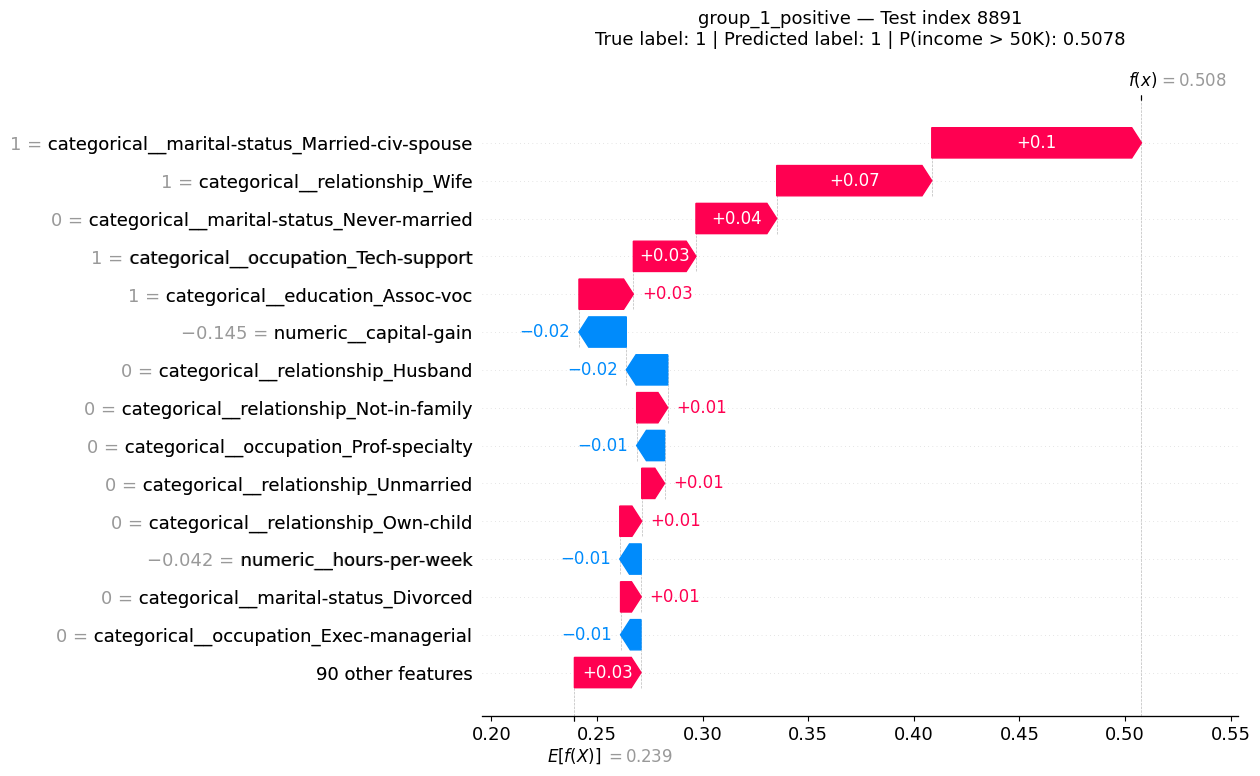

Case: group_1_negative | Test index: 4876
True label: 0 | Predicted label: 0 | P(income > 50K): 0.4995


,age,education,education-num,marital-status,occupation,relationship,sex,race,hours-per-week,capital-gain,capital-loss
4876,25,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Female,White,50,0,0


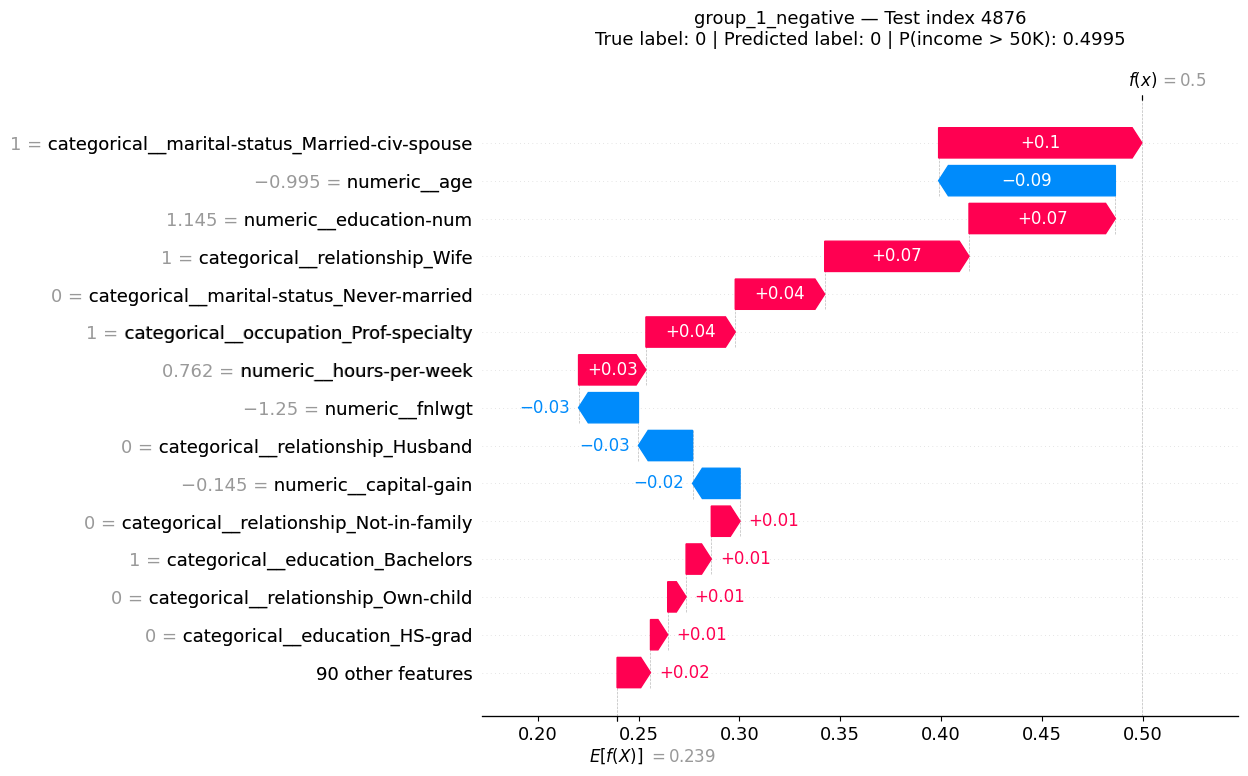

Case: group_2_negative | Test index: 9631
True label: 0 | Predicted label: 0 | P(income > 50K): 0.4997


,age,education,education-num,marital-status,occupation,relationship,sex,race,hours-per-week,capital-gain,capital-loss
9631,49,HS-grad,9,Married-civ-spouse,Transport-moving,Husband,Male,White,50,0,0


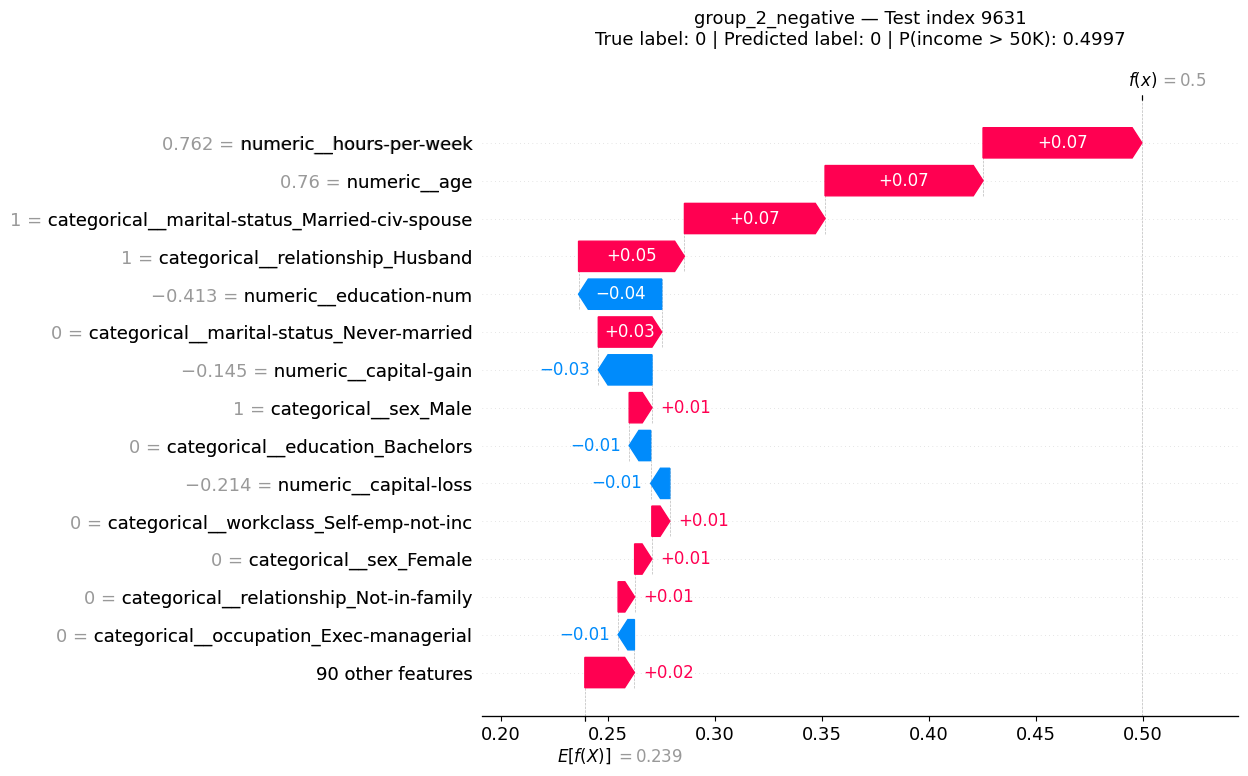


Local SHAP explanation table


,case_name,test_index,true_label,predicted_label,predicted_probability,rank,feature,raw_feature,transformed_feature_value,shap_value,effect_direction
0,group_1_positive,8891,1,1,0.507776,1,categorical__marital-status_Married-civ-spouse,marital-status,1.000000,0.099287,increases positive prediction
1,group_1_positive,8891,1,1,0.507776,2,categorical__relationship_Wife,relationship,1.000000,0.073421,increases positive prediction
2,group_1_positive,8891,1,1,0.507776,3,categorical__marital-status_Never-married,marital-status,0.000000,0.038221,increases positive prediction
3,group_1_positive,8891,1,1,0.507776,4,categorical__occupation_Tech-support,occupation,1.000000,0.029640,increases positive prediction
4,group_1_positive,8891,1,1,0.507776,5,categorical__education_Assoc-voc,education,1.000000,0.025745,increases positive prediction
5,group_1_positive,8891,1,1,0.507776,6,numeric__capital-gain,capital-gain,-0.144585,-0.022407,decreases positive prediction
6,group_1_positive,8891,1,1,0.507776,7,categorical__relationship_Husband,relationship,0.000000,-0.019612,decreases positive prediction
7,group_1_positive,8891,1,1,0.507776,8,categorical__relationship_Not-in-family,relationship,0.000000,0.014710,increases positive prediction
8,group_1_positive,8891,1,1,0.507776,9,categorical__occupation_Prof-specialty,occupation,0.000000,-0.013221,decreases positive prediction
9,group_1_positive,8891,1,1,0.507776,10,categorical__relationship_Unmarried,relationship,0.000000,0.010832,increases positive prediction



Local SHAP aggregated by original raw feature


,case_name,test_index,rank,raw_feature,summed_shap_value,effect_direction
0,group_1_positive,8891,1,marital-status,0.150055,increases positive prediction
1,group_1_positive,8891,2,relationship,0.091131,increases positive prediction
2,group_1_positive,8891,3,occupation,0.027968,increases positive prediction
3,group_1_positive,8891,4,education,0.026276,increases positive prediction
4,group_1_positive,8891,5,capital-gain,-0.022407,decreases positive prediction
5,group_1_positive,8891,6,hours-per-week,-0.010177,decreases positive prediction
6,group_1_positive,8891,7,education-num,0.009644,increases positive prediction
7,group_1_positive,8891,8,sex,0.007955,increases positive prediction
8,group_1_positive,8891,9,capital-loss,-0.006763,decreases positive prediction
9,group_1_positive,8891,10,race,0.006151,increases positive prediction



SHAP additivity verification


,case_name,test_index,true_label,predicted_label,base_value,sum_shap_values,base_plus_shap,model_probability_class_1,absolute_difference
0,group_1_positive,8891,1,1,0.239301,0.268476,0.507776,0.507776,1.037326e-11
1,group_1_negative,4876,0,0,0.239301,0.260246,0.499547,0.499547,2.479672e-11
2,group_2_negative,9631,0,0,0.239301,0.260364,0.499665,0.499665,6.708520e-10



Maximum absolute difference between SHAP reconstruction and model probability: 6.709e-10
SHAP verification passed successfully.


In [ ]:
def positive_expected_value(explainer) -> float:
    """Return the expected value for the positive class."""
    # Normalize scalar and class-wise expected values into a consistent array.
    expected = np.asarray(explainer.expected_value)
    if expected.ndim == 0:
        return float(expected)
    return float(expected.reshape(-1)[1])


def transformed_name_to_raw_feature(transformed_name: str) -> str:
    """Map a ColumnTransformer output name back to its original raw feature."""
    # Numeric transformed names preserve the raw column after the transformer prefix.
    if transformed_name.startswith("numeric__"):
        return transformed_name.split("__", 1)[1]

    # Match one-hot encoded names against the longest categorical column names first.
    suffix = transformed_name.split("__", 1)[-1]
    for column in sorted(CATEGORICAL_COLUMNS, key=len, reverse=True):
        if suffix == column or suffix.startswith(f"{column}_"):
            return column
    return suffix


# Define the original feature values displayed for each local explanation case.
RAW_FEATURES_TO_DISPLAY = [
    "age",
    "education",
    "education-num",
    "marital-status",
    "occupation",
    "relationship",
    "sex",
    "race",
    "hours-per-week",
    "capital-gain",
    "capital-loss",
]

# Accumulate transformed-feature explanations, raw-feature summaries, and additivity checks.
local_records = []
raw_feature_records = []
verification_records = []

# Generate a local SHAP explanation for every predefined test case.
for case in LOCAL_CASES:
    case_name = case["case_name"]
    index = case["index"]
    raw_row = X_test.loc[[index]]

    # Obtain the model's positive-class probability, binary prediction, and true label.
    model_probability = float(BLACK_BOX_MODEL.predict_proba(raw_row)[0, 1])
    model_prediction = int(model_probability >= 0.5)
    true_label = int(y_test.loc[index])

    print("=" * 90)
    print(f"Case: {case_name} | Test index: {index}")
    print(
        f"True label: {true_label} | Predicted label: {model_prediction} | "
        f"P(income > 50K): {model_probability:.4f}"
    )
    display(raw_row[RAW_FEATURES_TO_DISPLAY])

    # Transform the raw row and extract positive-class SHAP values.
    transformed_row = rf_preprocessor.transform(raw_row)
    local_values = positive_class_shap(
        tree_explainer.shap_values(transformed_row)
    )[0]

    # Reconstruct the predicted probability from the SHAP base value and contributions.
    base_value = positive_expected_value(tree_explainer)
    shap_reconstructed_probability = base_value + local_values.sum()
    absolute_difference = abs(
        shap_reconstructed_probability - model_probability
    )

    # Record the SHAP additivity verification values for this case.
    verification_records.append({
        "case_name": case_name,
        "test_index": index,
        "true_label": true_label,
        "predicted_label": model_prediction,
        "base_value": base_value,
        "sum_shap_values": float(local_values.sum()),
        "base_plus_shap": float(shap_reconstructed_probability),
        "model_probability_class_1": model_probability,
        "absolute_difference": float(absolute_difference),
    })

    # Build and save a transformed-feature waterfall explanation.
    explanation = shap.Explanation(
        values=local_values,
        base_values=base_value,
        data=transformed_row[0],
        feature_names=transformed_feature_names,
    )
    shap.plots.waterfall(explanation, max_display=15, show=False)
    figure = plt.gcf()
    figure.set_size_inches(14, 8)
    plt.title(
        f"{case_name} — Test index {index}\n"
        f"True label: {true_label} | Predicted label: {model_prediction} | "
        f"P(income > 50K): {model_probability:.4f}",
        fontsize=13,
        pad=18,
    )
    plt.subplots_adjust(left=0.43, right=0.97, top=0.87, bottom=0.10)
    figure.savefig(
        RESULTS_ROOT / f"local_shap_{case_name}.png",
        dpi=200,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(figure)

    # Rank transformed features by the absolute magnitude of their SHAP contributions.
    top_feature_indices = np.argsort(np.abs(local_values))[::-1][:10]
    for rank, feature_index in enumerate(top_feature_indices, start=1):
        local_records.append({
            "case_name": case_name,
            "test_index": index,
            "true_label": true_label,
            "predicted_label": model_prediction,
            "predicted_probability": model_probability,
            "rank": rank,
            "feature": transformed_feature_names[feature_index],
            "raw_feature": transformed_name_to_raw_feature(
                transformed_feature_names[feature_index]
            ),
            "transformed_feature_value": transformed_row[0, feature_index],
            "shap_value": local_values[feature_index],
            "effect_direction": (
                "increases positive prediction"
                if local_values[feature_index] > 0
                else "decreases positive prediction"
            ),
        })

    # Aggregate one-hot and transformed contributions back to original raw features.
    per_raw_feature = {}
    for transformed_name, shap_value in zip(
        transformed_feature_names,
        local_values,
    ):
        raw_feature = transformed_name_to_raw_feature(transformed_name)
        per_raw_feature[raw_feature] = per_raw_feature.get(raw_feature, 0.0) + float(shap_value)

    # Rank the aggregated raw-feature contributions by absolute magnitude.
    for rank, (raw_feature, summed_shap) in enumerate(
        sorted(per_raw_feature.items(), key=lambda item: abs(item[1]), reverse=True),
        start=1,
    ):
        raw_feature_records.append({
            "case_name": case_name,
            "test_index": index,
            "rank": rank,
            "raw_feature": raw_feature,
            "summed_shap_value": summed_shap,
            "effect_direction": (
                "increases positive prediction"
                if summed_shap > 0
                else "decreases positive prediction"
            ),
        })

# Persist and display transformed-feature local explanations.
local_explanation_table = pd.DataFrame(local_records)
local_explanation_table.to_csv(
    RESULTS_ROOT / "local_shap_explanations.csv",
    index=False,
)
print("\nLocal SHAP explanation table")
display(local_explanation_table)

# Persist and display SHAP contributions aggregated by original raw feature.
local_raw_feature_table = pd.DataFrame(raw_feature_records)
local_raw_feature_table.to_csv(
    RESULTS_ROOT / "local_shap_raw_feature_summary.csv",
    index=False,
)
print("\nLocal SHAP aggregated by original raw feature")
display(local_raw_feature_table.groupby("case_name").head(10))

# Persist and display the probability reconstruction checks.
verification_table = pd.DataFrame(verification_records)
verification_table.to_csv(
    RESULTS_ROOT / "local_shap_verification.csv",
    index=False,
)
print("\nSHAP additivity verification")
display(verification_table)

# Check the largest deviation between SHAP reconstruction and model output.
maximum_difference = verification_table["absolute_difference"].max()
print(
    "\nMaximum absolute difference between SHAP reconstruction and model probability:",
    f"{maximum_difference:.3e}",
)
if maximum_difference < 1e-6:
    print("SHAP verification passed successfully.")
else:
    print("Warning: SHAP reconstruction difference is larger than expected.")

## Counterfactual explanation and recourse

In [ ]:
# Map encoded education levels to their corresponding Adult dataset labels.
EDUCATION_NUM_TO_LABEL = {
    1: "Preschool",
    2: "1st-4th",
    3: "5th-6th",
    4: "7th-8th",
    5: "9th",
    6: "10th",
    7: "11th",
    8: "12th",
    9: "HS-grad",
    10: "Some-college",
    11: "Assoc-voc",
    12: "Assoc-acdm",
    13: "Bachelors",
    14: "Masters",
    15: "Prof-school",
    16: "Doctorate",
}
# Build the reverse lookup used to translate education labels back to numeric levels.
EDUCATION_LABEL_TO_NUM = {
    label: number for number, label in EDUCATION_NUM_TO_LABEL.items()
}

# Define the features considered actionable, mutable by the model, or immutable.
ACTIONABLE_ACTIONS = ["education_level", "hours-per-week", "capital-gain"]
MUTABLE_MODEL_COLUMNS = [
    "education",
    "education-num",
    "hours-per-week",
    "capital-gain",
]
IMMUTABLE_FEATURES = ["sex", "race", "age"]

# Assign relative costs to the permitted counterfactual action types.
ACTION_COST_WEIGHTS = {
    "education_level": 3.0,
    "hours-per-week": 1.0,
    "capital-gain": 2.0,
}


def synchronized_education(candidate: pd.Series, education_number: int) -> pd.Series:
    # Normalize the requested education level before validating and applying it.
    education_number = int(education_number)
    if education_number not in EDUCATION_NUM_TO_LABEL:
        raise ValueError(f"Invalid education-num: {education_number}")
    # Update both linked education representations to preserve internal consistency.
    candidate["education-num"] = education_number
    candidate["education"] = EDUCATION_NUM_TO_LABEL[education_number]
    return candidate


def education_is_consistent(row: pd.Series) -> bool:
    # Recover the nearest integer education code and compare it with the stored label.
    education_number = int(round(float(row["education-num"])))
    expected_label = EDUCATION_NUM_TO_LABEL.get(education_number)
    return expected_label is not None and str(row["education"]) == expected_label


def candidate_values(row: pd.Series, target_positive: bool) -> dict[str, list[int]]:
    # Read the current actionable values as integer starting points for the search grids.
    education_number = int(round(float(row["education-num"])))
    hours = int(round(float(row["hours-per-week"])))
    capital_gain = int(round(float(row["capital-gain"])))

    # Use a fixed capital-gain grid spanning no gain through the dataset maximum.
    gain_grid = [0, 1000, 3000, 5000, 10000, 20000, 50000, 99999]

    # Positive recourse searches only non-decreasing changes in the selected features.
    if target_positive:
        return {
            "education-num": list(range(education_number, 17)),
            "hours-per-week": sorted(
                set([hours] + list(range(max(hours, 20), 81, 5)))
            ),
            "capital-gain": sorted(
                set([capital_gain] + [value for value in gain_grid if value >= capital_gain])
            ),
        }

    # For a positive case, this is a contrastive explanation rather than a recommendation.
    # A lower educational credential may be used to explain the decision boundary, but is
    # explicitly marked as non-actionable in the final assessment.
    return {
        "education-num": list(range(1, education_number + 1)),
        "hours-per-week": sorted(
            set([hours] + list(range(5, max(hours, 5) + 1, 5)))
        ),
        "capital-gain": sorted(set([0, capital_gain])),
    }


def counterfactual_cost(original: pd.Series, candidate: pd.Series) -> float:
    # Normalize each feature change by its observed or encoded range.
    education_change = abs(
        float(candidate["education-num"]) - float(original["education-num"])
    ) / 15.0
    hours_change = abs(
        float(candidate["hours-per-week"]) - float(original["hours-per-week"])
    ) / 79.0
    gain_change = abs(
        float(candidate["capital-gain"]) - float(original["capital-gain"])
    ) / 99999.0

    # Combine normalized changes using the configured action-specific weights.
    return float(
        ACTION_COST_WEIGHTS["education_level"] * education_change
        + ACTION_COST_WEIGHTS["hours-per-week"] * hours_change
        + ACTION_COST_WEIGHTS["capital-gain"] * gain_change
    )


def changed_actions(original: pd.Series, candidate: pd.Series) -> dict[str, Any]:
    # Collect only actionable values that differ between the original and candidate rows.
    changes: dict[str, Any] = {}

    # Treat education and education-num as one synchronized action.
    if int(original["education-num"]) != int(candidate["education-num"]):
        changes["education_level"] = {
            "from": {
                "education": str(original["education"]),
                "education-num": int(original["education-num"]),
            },
            "to": {
                "education": str(candidate["education"]),
                "education-num": int(candidate["education-num"]),
            },
        }

    # Record changes to the remaining independently represented actionable features.
    for feature in ["hours-per-week", "capital-gain"]:
        if float(original[feature]) != float(candidate[feature]):
            changes[feature] = {
                "from": float(original[feature]),
                "to": float(candidate[feature]),
            }

    return changes


def assess_counterfactual(
    original: pd.Series,
    candidate: pd.Series,
    counterfactual_type: str,
    changes: dict[str, Any],
) -> dict[str, Any]:
    # Separate non-prescriptive negative contrasts from positive recourse assessments.
    if counterfactual_type == "contrastive_to_negative":
        return {
            "practicality_assessment": (
                "Contrastive explanation only. It explains how the model boundary "
                "could change but is not a recommended action for the person."
            ),
            "ethical_assessment": (
                "Not a recourse recommendation. Reducing education, "
                "income-related gains, or work hours should not be prescribed "
                "to obtain a negative decision."
            ),
            "fully_under_individual_control": False,
        }

    # Accumulate practical concerns and track whether every action is fully controllable.
    concerns: list[str] = []
    fully_controllable = True

    # Assess the feasibility of any proposed education-level change.
    if "education_level" in changes:
        level_increase = (
            changes["education_level"]["to"]["education-num"]
            - changes["education_level"]["from"]["education-num"]
        )

        # Education requires time, money and access, so it is not fully
        # under the individual's immediate control.
        fully_controllable = False

        if level_increase > 2:
            concerns.append(
                "The proposed educational change is long-term, "
                "resource intensive, and only partially under the "
                "individual's control."
            )
        else:
            concerns.append(
                "The proposed educational change may require time, money, "
                "institutional access, and personal support; therefore, it is "
                "only partially under the individual's control."
            )

    # Assess health, caregiving, employer, and availability constraints on work-hour changes.
    if "hours-per-week" in changes:
        new_hours = float(changes["hours-per-week"]["to"])
        old_hours = float(changes["hours-per-week"]["from"])
        delta_hours = new_hours - old_hours

        fully_controllable = False

        if new_hours > 60 or delta_hours > 15:
            concerns.append(
                "The proposed work-hour increase may be unhealthy or "
                "incompatible with caregiving and personal responsibilities."
            )
        else:
            concerns.append(
                "Work hours depend on employer decisions, job availability, "
                "health, and personal constraints."
            )

    # Treat capital gain as dependent on assets and market access rather than immediate control.
    if "capital-gain" in changes:
        fully_controllable = False

        concerns.append(
            "Capital gain is not a directly or immediately controllable "
            "action for most individuals and depends on assets, investment "
            "opportunities, and market conditions."
        )

    # Flag an unexpected result when no actionable feature changed.
    if not concerns:
        concerns.append(
            "No actionable feature change was identified, which is unexpected "
            "for a valid label-changing counterfactual."
        )
        fully_controllable = False

    # Return the practical, ethical, and controllability assessment for the candidate.
    return {
        "practicality_assessment": " ".join(concerns),
        "ethical_assessment": (
            "The proposal does not change sex, race, or age. Nevertheless, "
            "a mathematically valid counterfactual should be interpreted as "
            "an explanation of model behavior rather than guaranteed or "
            "prescriptive real-world advice."
        ),
        "fully_under_individual_control": fully_controllable,
    }


def generate_counterfactual(
    row: pd.Series,
    model: Pipeline,
    threshold: float = 0.5,
) -> dict[str, Any]:
    # Evaluate the original row and determine which side of the threshold must be reached.
    original_frame = row.to_frame().T
    original_probability = float(model.predict_proba(original_frame)[0, 1])
    original_prediction = int(original_probability >= threshold)
    target_positive = original_prediction == 0
    grids = candidate_values(row, target_positive)

    # Enumerate the Cartesian product of all permitted actionable feature values.
    candidates = []
    for education_number, hours, capital_gain in itertools.product(
        grids["education-num"],
        grids["hours-per-week"],
        grids["capital-gain"],
    ):
        candidate = row.copy()
        candidate = synchronized_education(candidate, education_number)
        candidate["hours-per-week"] = int(hours)
        candidate["capital-gain"] = int(capital_gain)
        candidates.append(candidate)

    # Score every generated candidate in one vectorized model prediction call.
    frame = pd.DataFrame(candidates)
    probabilities = model.predict_proba(frame)[:, 1]
    valid_mask = probabilities >= threshold if target_positive else probabilities < threshold
    counterfactual_type = (
        "recourse_to_positive" if target_positive else "contrastive_to_negative"
    )

    # Return an explicit failure record when the restricted search space cannot flip the label.
    if not np.any(valid_mask):
        return {
            "found": False,
            "counterfactual_type": counterfactual_type,
            "original_probability": original_probability,
            "original_prediction": original_prediction,
            "candidate_count": int(len(frame)),
            "reason": (
                "No valid counterfactual was found in the restricted and internally "
                "consistent search space."
            ),
        }

    # Rank valid candidates by cost, number of changes, and proximity to the threshold.
    valid_indices = np.where(valid_mask)[0]
    scored_candidates = []
    for candidate_index in valid_indices:
        candidate = frame.iloc[candidate_index]
        changes = changed_actions(row, candidate)
        scored_candidates.append((
            counterfactual_cost(row, candidate),
            len(changes),
            abs(float(probabilities[candidate_index]) - threshold),
            int(candidate_index),
        ))

    # Select the lexicographically smallest scored candidate.
    _, _, _, best_index = min(scored_candidates)
    best = frame.iloc[best_index]
    changes = changed_actions(row, best)

    # Verify that immutable attributes were preserved and education fields remain synchronized.
    immutable_unchanged = all(
        str(row[feature]) == str(best[feature]) for feature in IMMUTABLE_FEATURES
    )
    consistency_passed = education_is_consistent(best)
    # Attach a context-aware practicality and ethics assessment to the selected candidate.
    assessment = assess_counterfactual(
        row,
        best,
        counterfactual_type,
        changes,
    )

    # Return the selected counterfactual together with validation and assessment metadata.
    return {
        "found": True,
        "counterfactual_type": counterfactual_type,
        "original_probability": original_probability,
        "original_prediction": original_prediction,
        "counterfactual_probability": float(probabilities[best_index]),
        "counterfactual_prediction": int(probabilities[best_index] >= threshold),
        "normalized_cost": float(counterfactual_cost(row, best)),
        "number_of_changed_actions": int(len(changes)),
        "candidate_count": int(len(frame)),
        "changes": json.dumps(changes, ensure_ascii=False),
        "immutable_features_unchanged": bool(immutable_unchanged),
        "education_consistency_passed": bool(consistency_passed),
        **assessment,
    }


# Generate counterfactual explanations for all predefined local cases.
counterfactual_records = []
for case in LOCAL_CASES:
    result = generate_counterfactual(
        X_test.loc[case["index"]],
        BLACK_BOX_MODEL,
    )
    counterfactual_records.append({
        "case_name": case["case_name"],
        "test_index": case["index"],
        "sex": str(X_test.loc[case["index"], "sex"]),
        **result,
    })

# Consolidate, persist, and display the counterfactual results.
counterfactual_table = pd.DataFrame(counterfactual_records)
counterfactual_table.to_csv(
    RESULTS_ROOT / "counterfactual_explanations.csv",
    index=False,
)
display(counterfactual_table)

# Warn when the constrained search fails for any required case.
if not counterfactual_table["found"].all():
    warnings.warn("At least one required case has no valid counterfactual.")
# Enforce consistency between the paired education representations.
if counterfactual_table.loc[counterfactual_table["found"], "education_consistency_passed"].eq(False).any():
    raise AssertionError("An inconsistent education / education-num pair was generated.")
# Enforce preservation of all explicitly immutable features.
if counterfactual_table.loc[counterfactual_table["found"], "immutable_features_unchanged"].eq(False).any():
    raise AssertionError("A counterfactual changed an immutable feature.")

# State the limitations of treating mathematical counterfactuals as real-world recourse.
print(
    "Ethical note: education and working hours may be partly actionable but can require "
    "substantial time, money, health capacity, employer cooperation, or caregiving "
    "flexibility. Capital gain is not directly controllable for many people. A mathematically "
    "valid counterfactual is therefore not automatically practical, ethical, or guaranteed "
    "to change a real-world outcome."
)

,case_name,test_index,sex,found,counterfactual_type,original_probability,original_prediction,counterfactual_probability,counterfactual_prediction,normalized_cost,number_of_changed_actions,candidate_count,changes,immutable_features_unchanged,education_consistency_passed,practicality_assessment,ethical_assessment,fully_under_individual_control
0,group_1_positive,8891,Female,True,contrastive_to_negative,0.507776,1,0.360173,0,0.200000,1,88,"{""education_level"": {""from"": {""education"": ""As...",True,True,Contrastive explanation only. It explains how ...,Not a recourse recommendation. Reducing educat...,False
1,group_1_negative,4876,Female,True,recourse_to_positive,0.499547,0,0.645201,1,0.200000,1,224,"{""education_level"": {""from"": {""education"": ""Ba...",True,True,The proposed educational change may require ti...,"The proposal does not change sex, race, or age...",False
2,group_2_negative,9631,Male,True,recourse_to_positive,0.499665,0,0.539621,1,0.189873,1,448,"{""hours-per-week"": {""from"": 50.0, ""to"": 65.0}}",True,True,The proposed work-hour increase may be unhealt...,"The proposal does not change sex, race, or age...",False


Ethical note: education and working hours may be partly actionable but can require substantial time, money, health capacity, employer cooperation, or caregiving flexibility. Capital gain is not directly controllable for many people. A mathematically valid counterfactual is therefore not automatically practical, ethical, or guaranteed to change a real-world outcome.


## Bias mitigation method 1 — Reweighing

In [ ]:
def compute_reweighing_weights(
    sensitive_values: pd.Series,
    labels: pd.Series,
) -> np.ndarray:
    # Convert sensitive groups and labels into aligned NumPy arrays.
    sensitive_array = sensitive_values.astype(str).to_numpy()
    label_array = labels.astype(int).to_numpy()

    # Estimate the marginal probability of each sensitive group.
    p_sensitive = {
        group: float(np.mean(sensitive_array == group))
        for group in pd.unique(sensitive_array)
    }
    # Estimate the marginal probability of each target label.
    p_label = {
        label: float(np.mean(label_array == label))
        for label in pd.unique(label_array)
    }
    # Estimate the joint probability of every sensitive-group and label combination.
    p_joint = {
        (group, label): float(
            np.mean((sensitive_array == group) & (label_array == label))
        )
        for group in pd.unique(sensitive_array)
        for label in pd.unique(label_array)
    }

    # Reject empty joint cells because their reweighing factors are undefined.
    zero_cells = [key for key, probability in p_joint.items() if probability == 0]
    if zero_cells:
        raise ValueError(f"Reweighing is undefined for empty sensitive-label cells: {zero_cells}")

    # Assign each sample the ratio of independent marginals to its observed joint probability.
    return np.array([
        p_sensitive[group] * p_label[label] / p_joint[(group, label)]
        for group, label in zip(sensitive_array, label_array)
    ])


# Compute training-sample weights using sex as the sensitive attribute.
weights = compute_reweighing_weights(X_train["sex"], y_train)
print("Weight range:", float(weights.min()), "to", float(weights.max()))
print("Mean weight:", float(weights.mean()))

# Train a Random Forest pipeline using the computed reweighing weights.
REWEIGHTED_RF = build_model_pipeline(X_train, "Random Forest")
start = time.perf_counter()
REWEIGHTED_RF.fit(X_train, y_train, model__sample_weight=weights)
reweighted_seconds = time.perf_counter() - start

# Generate positive-class probabilities and fixed-threshold predictions.
reweighted_probabilities = REWEIGHTED_RF.predict_proba(X_test)[:, 1]
reweighted_predictions = (reweighted_probabilities >= 0.5).astype(int)

Weight range: 0.7857063533687054 to 2.236115568894001
Mean weight: 1.0000000000000002


## Bias mitigation method 2 — Threshold adjustment per sex group

In [ ]:
def apply_group_thresholds(
    probabilities: np.ndarray,
    sensitive_values: pd.Series | np.ndarray,
    thresholds: dict[str, float],
) -> np.ndarray:
    # Convert probabilities and sensitive-group values into aligned NumPy arrays.
    probability_array = np.asarray(probabilities).astype(float)
    sensitive_array = np.asarray(sensitive_values).astype(str)

    # Use the configured fallback threshold for groups without an explicit value.
    default_threshold = thresholds.get("__default__", 0.5)

    # Apply the threshold associated with each sample's sensitive group.
    return np.array([
        int(probability >= thresholds.get(group, default_threshold))
        for probability, group in zip(probability_array, sensitive_array)
    ])


def search_binary_group_thresholds(
    y_true: pd.Series,
    probabilities: np.ndarray,
    sensitive_values: pd.Series,
    accuracy_tolerance: float = 0.03,
    recall_tolerance: float = 0.05,
    group_tpr_tolerance: float = 0.05,
):
    """Select thresholds on validation data with explicit anti-leveling-down constraints."""
    # Identify the two sensitive groups used in the threshold search.
    groups = sorted(sensitive_values.astype(str).unique())
    if len(groups) != 2:
        raise ValueError("This threshold search expects exactly two groups.")

    # Establish the common-threshold baseline used by the performance constraints.
    baseline_predictions = (np.asarray(probabilities) >= 0.5).astype(int)
    baseline_accuracy = accuracy_score(y_true, baseline_predictions)
    baseline_recall = recall_score(y_true, baseline_predictions, zero_division=0)
    baseline_group_table = group_metric_table(
        y_true,
        probabilities,
        sensitive_values,
        predictions=baseline_predictions,
    ).set_index("group")

    # Define the candidate threshold values evaluated for both groups.
    grid = np.round(np.arange(0.20, 0.81, 0.02), 2)

    def enumerate_candidates(enforce_group_tpr_constraint: bool) -> pd.DataFrame:
        # Evaluate every pair of group-specific thresholds.
        records = []
        for threshold_0, threshold_1 in itertools.product(grid, grid):
            thresholds = {
                groups[0]: float(threshold_0),
                groups[1]: float(threshold_1),
                "__default__": 0.5,
            }
            predictions = apply_group_thresholds(
                probabilities,
                sensitive_values,
                thresholds,
            )
            accuracy = accuracy_score(y_true, predictions)
            recall = recall_score(y_true, predictions, zero_division=0)

            # Exclude candidates that exceed the allowed overall performance losses.
            if accuracy < baseline_accuracy - accuracy_tolerance:
                continue
            if recall < baseline_recall - recall_tolerance:
                continue

            # Compute group-level metrics under the candidate thresholds.
            table = group_metric_table(
                y_true,
                probabilities,
                sensitive_values,
                predictions=predictions,
            ).set_index("group")

            # Measure each group's TPR reduction relative to the common-threshold baseline.
            group_tpr_drops = {
                group: float(
                    baseline_group_table.loc[group, "tpr_recall"]
                    - table.loc[group, "tpr_recall"]
                )
                for group in groups
            }

            # Reject candidates that reduce any group's TPR beyond the permitted amount.
            if enforce_group_tpr_constraint and any(
                drop > group_tpr_tolerance for drop in group_tpr_drops.values()
            ):
                continue

            # Compute fairness gaps and group-specific selection-rate reductions.
            table_reset = table.reset_index()
            gaps = fairness_gap_summary(table_reset)
            positive_rate_drops = {
                group: float(
                    baseline_group_table.loc[group, "positive_prediction_rate"]
                    - table.loc[group, "positive_prediction_rate"]
                )
                for group in groups
            }

            # Penalize reductions in group TPR to discourage leveling down.
            leveling_down_penalty = sum(
                max(0.0, drop) for drop in group_tpr_drops.values()
            )

            # Combine fairness disparities, leveling-down risk, and performance losses.
            objective = (
                gaps["equalized_odds_difference"]
                + 0.25 * gaps["demographic_parity_difference"]
                + 0.35 * leveling_down_penalty
                + 0.10 * max(0.0, baseline_accuracy - accuracy)
                + 0.10 * max(0.0, baseline_recall - recall)
            )

            # Store the candidate thresholds, constraints, and evaluation metrics.
            records.append({
                f"threshold_{groups[0]}": threshold_0,
                f"threshold_{groups[1]}": threshold_1,
                "accuracy": accuracy,
                "recall": recall,
                "objective": objective,
                "leveling_down_penalty": leveling_down_penalty,
                f"tpr_drop_{groups[0]}": group_tpr_drops[groups[0]],
                f"tpr_drop_{groups[1]}": group_tpr_drops[groups[1]],
                f"positive_rate_drop_{groups[0]}": positive_rate_drops[groups[0]],
                f"positive_rate_drop_{groups[1]}": positive_rate_drops[groups[1]],
                **gaps,
            })

        return pd.DataFrame(records)

    # First search under the strict per-group anti-leveling-down constraint.
    search_mode = "strict_anti_leveling_down"
    table = enumerate_candidates(enforce_group_tpr_constraint=True)

    # Fall back to the relaxed search only when no strict candidate is feasible.
    if table.empty:
        warnings.warn(
            "No threshold pair satisfied the strict per-group TPR constraint. "
            "Using the relaxed search and flagging the result for explicit discussion."
        )
        search_mode = "relaxed_fallback"
        table = enumerate_candidates(enforce_group_tpr_constraint=False)

    if table.empty:
        raise RuntimeError("No threshold pair satisfied the performance constraints.")

    # Rank feasible candidates by objective, fairness gap, and predictive performance.
    table = table.sort_values(
        ["objective", "equalized_odds_difference", "accuracy", "recall"],
        ascending=[True, True, False, False],
    )

    # Extract the highest-ranked threshold pair.
    best = table.iloc[0]
    thresholds = {
        groups[0]: float(best[f"threshold_{groups[0]}"]),
        groups[1]: float(best[f"threshold_{groups[1]}"]),
        "__default__": 0.5,
    }

    # Record the baseline values and constraints governing the search.
    search_metadata = {
        "search_mode": search_mode,
        "baseline_accuracy": float(baseline_accuracy),
        "baseline_recall": float(baseline_recall),
        "accuracy_tolerance": float(accuracy_tolerance),
        "recall_tolerance": float(recall_tolerance),
        "group_tpr_tolerance": float(group_tpr_tolerance),
    }
    return thresholds, table, search_metadata


# Generate validation probabilities for threshold selection.
validation_probabilities = BLACK_BOX_MODEL.predict_proba(X_validation)[:, 1]

# Select group-specific thresholds using validation data only.
(
    BEST_GROUP_THRESHOLDS,
    threshold_search_table,
    THRESHOLD_SEARCH_METADATA,
) = search_binary_group_thresholds(
    y_validation,
    validation_probabilities,
    X_validation["sex"],
    accuracy_tolerance=CONFIG["threshold_accuracy_tolerance"],
    recall_tolerance=CONFIG["threshold_recall_tolerance"],
    group_tpr_tolerance=CONFIG["threshold_group_tpr_tolerance"],
)

# Persist the complete ranked validation threshold search.
threshold_search_table.to_csv(
    RESULTS_ROOT / "threshold_search_validation.csv",
    index=False,
)

# Persist the search mode, baseline metrics, and constraint tolerances.
with open(
    RESULTS_ROOT / "threshold_search_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(THRESHOLD_SEARCH_METADATA, file, indent=2)

print("Selected thresholds:", BEST_GROUP_THRESHOLDS)
print("Threshold-search mode:", THRESHOLD_SEARCH_METADATA["search_mode"])
display(threshold_search_table.head(10))

# Apply the validation-selected thresholds to the Random Forest test probabilities.
threshold_predictions = apply_group_thresholds(
    rf_probabilities,
    X_test["sex"],
    BEST_GROUP_THRESHOLDS,
)

Selected thresholds: {'Female': 0.32, 'Male': 0.5, '__default__': 0.5}
Threshold-search mode: strict_anti_leveling_down


,threshold_Female,threshold_Male,accuracy,recall,objective,leveling_down_penalty,tpr_drop_Female,tpr_drop_Male,positive_rate_drop_Female,positive_rate_drop_Male,group_count,demographic_parity_difference,equal_opportunity_difference,equalized_odds_difference,predictive_parity_difference,fpr_difference,fnr_difference,calibration_gap_difference,brier_score_difference,ece_difference
77,0.32,0.50,0.862316,0.650267,0.073334,0.000000,-0.164983,0.000000,-0.044643,0.000000,2,0.133721,0.039509,0.039686,0.105269,0.039686,0.039509,0.004487,0.06129,0.015332
89,0.34,0.50,0.862572,0.647594,0.077544,0.000000,-0.148148,0.000000,-0.039984,0.000000,2,0.138379,0.022674,0.042757,0.095561,0.042757,0.022674,0.004487,0.06129,0.015332
52,0.28,0.48,0.862060,0.679679,0.079391,0.000000,-0.198653,-0.028608,-0.055901,-0.015843,2,0.138306,0.044572,0.044572,0.119114,0.041714,0.044572,0.004487,0.06129,0.015332
114,0.38,0.52,0.862188,0.625668,0.081601,0.022886,-0.131313,0.022886,-0.033773,0.012025,2,0.132565,0.028725,0.040219,0.084889,0.040219,0.028725,0.004487,0.06129,0.015332
101,0.36,0.50,0.863468,0.647059,0.081838,0.000000,-0.144781,0.000000,-0.036491,0.000000,2,0.141873,0.019307,0.046268,0.078199,0.046268,0.019307,0.004487,0.06129,0.015332
102,0.36,0.52,0.862316,0.627807,0.082883,0.022886,-0.144781,0.022886,-0.036491,0.012025,2,0.129848,0.042193,0.042193,0.087694,0.038903,0.042193,0.004487,0.06129,0.015332
64,0.30,0.48,0.862700,0.676471,0.082947,0.000000,-0.178451,-0.028608,-0.049301,-0.015843,2,0.144905,0.024370,0.046541,0.104432,0.046541,0.024370,0.004487,0.06129,0.015332
113,0.38,0.50,0.863340,0.644920,0.083847,0.000000,-0.131313,0.000000,-0.033773,0.000000,2,0.144591,0.005839,0.047584,0.075394,0.047584,0.005839,0.004487,0.06129,0.015332
90,0.34,0.52,0.861420,0.628342,0.085466,0.022886,-0.148148,0.022886,-0.039984,0.012025,2,0.126354,0.045561,0.045561,0.105055,0.035392,0.045561,0.004487,0.06129,0.015332
65,0.30,0.50,0.861804,0.652406,0.085512,0.000000,-0.178451,0.000000,-0.049301,0.000000,2,0.129063,0.052977,0.052977,0.117367,0.036176,0.052977,0.004487,0.06129,0.015332


## Before-and-after mitigation comparison

In [23]:
MITIGATION_OUTPUTS = {
    "Baseline Random Forest": {
        "probabilities": rf_probabilities,
        "predictions": rf_predictions,
        "training_seconds": MODEL_OUTPUTS["Random Forest"]["training_seconds"],
    },
    "Reweighted Random Forest": {
        "probabilities": reweighted_probabilities,
        "predictions": reweighted_predictions,
        "training_seconds": reweighted_seconds,
    },
    "Sex-specific Threshold Adjustment": {
        "probabilities": rf_probabilities,
        "predictions": threshold_predictions,
        "training_seconds": 0.0,
    },
}

mitigation_performance_records = []
mitigation_fairness_records = []
mitigation_group_tables: dict[tuple[str, str], pd.DataFrame] = {}

for method_name, outputs in MITIGATION_OUTPUTS.items():
    mitigation_performance_records.append({
        "method": method_name,
        **predictive_metrics(
            y_test,
            outputs["probabilities"],
            outputs["predictions"],
        ),
        "training_seconds": outputs["training_seconds"],
    })

    for attribute in SENSITIVE_ATTRIBUTES:
        table = group_metric_table(
            y_test,
            outputs["probabilities"],
            X_test[attribute],
            predictions=outputs["predictions"],
        )
        mitigation_group_tables[(method_name, attribute)] = table
        table.to_csv(
            RESULTS_ROOT
            / f"mitigation_{method_name.lower().replace(' ', '_').replace('-', '_')}_{attribute}_groups.csv",
            index=False,
        )
        mitigation_fairness_records.append({
            "method": method_name,
            "sensitive_attribute": attribute,
            **fairness_gap_summary(table),
        })

mitigation_performance_table = pd.DataFrame(mitigation_performance_records)
mitigation_fairness_table = pd.DataFrame(mitigation_fairness_records)
mitigation_performance_table.to_csv(
    RESULTS_ROOT / "mitigation_performance.csv",
    index=False,
)
mitigation_fairness_table.to_csv(
    RESULTS_ROOT / "mitigation_fairness.csv",
    index=False,
)

display(mitigation_performance_table)
display(mitigation_fairness_table)
for method_name in MITIGATION_OUTPUTS:
    print(f"\n{method_name} — sex group details")
    display(mitigation_group_tables[(method_name, "sex")])

# Explicit test-set diagnostics for leveling down.
baseline_sex_table = mitigation_group_tables[(
    "Baseline Random Forest",
    "sex",
)].set_index("group")
leveling_down_records = []
for method_name in [
    "Reweighted Random Forest",
    "Sex-specific Threshold Adjustment",
]:
    method_table = mitigation_group_tables[(method_name, "sex")].set_index("group")
    for group in baseline_sex_table.index:
        leveling_down_records.append({
            "method": method_name,
            "group": group,
            "baseline_tpr": baseline_sex_table.loc[group, "tpr_recall"],
            "method_tpr": method_table.loc[group, "tpr_recall"],
            "delta_tpr": (
                method_table.loc[group, "tpr_recall"]
                - baseline_sex_table.loc[group, "tpr_recall"]
            ),
            "baseline_positive_prediction_rate": baseline_sex_table.loc[
                group, "positive_prediction_rate"
            ],
            "method_positive_prediction_rate": method_table.loc[
                group, "positive_prediction_rate"
            ],
            "delta_positive_prediction_rate": (
                method_table.loc[group, "positive_prediction_rate"]
                - baseline_sex_table.loc[group, "positive_prediction_rate"]
            ),
        })

leveling_down_table = pd.DataFrame(leveling_down_records)
leveling_down_table.to_csv(
    RESULTS_ROOT / "leveling_down_diagnostics.csv",
    index=False,
)
display(leveling_down_table)

,method,accuracy,precision,recall,f1,roc_auc,brier_score,training_seconds
0,Baseline Random Forest,0.866926,0.779333,0.619333,0.690181,0.917019,0.095234,1.807682
1,Reweighted Random Forest,0.860784,0.778474,0.584688,0.667807,0.913703,0.097282,2.009848
2,Sex-specific Threshold Adjustment,0.863446,0.750000,0.644140,0.693051,0.917019,0.095234,0.000000


,method,sensitive_attribute,group_count,demographic_parity_difference,equal_opportunity_difference,equalized_odds_difference,predictive_parity_difference,fpr_difference,fnr_difference,calibration_gap_difference,brier_score_difference,ece_difference
0,Baseline Random Forest,sex,2,0.173971,0.117311,0.117311,0.003354,0.059909,0.117311,0.000837,0.062941,0.011331
1,Baseline Random Forest,race,5,0.166498,0.199301,0.199301,0.208333,0.084529,0.199301,0.070909,0.047882,0.068651
2,Reweighted Random Forest,sex,2,0.106435,0.069231,0.069231,0.152210,0.016899,0.069231,0.007575,0.060986,0.009440
3,Reweighted Random Forest,race,5,0.163209,0.303030,0.303030,0.141834,0.093992,0.303030,0.067228,0.051846,0.059599
4,Sex-specific Threshold Adjustment,sex,2,0.128364,0.040727,0.040727,0.150989,0.028423,0.040727,0.000837,0.062941,0.011331
5,Sex-specific Threshold Adjustment,race,5,0.183198,0.237762,0.237762,0.096398,0.097162,0.237762,0.070909,0.047882,0.068651



Baseline Random Forest — sex group details


,group,n,n_actual_positive,n_actual_negative,n_predicted_positive,base_rate,positive_prediction_rate,accuracy,precision,tpr_recall,fpr,fnr,mean_predicted_probability,calibration_in_the_large,calibration_gap,brier_score,ece,ece_n_bins,low_support_warning
0,Female,3289,367,2922,246,0.111584,0.074795,0.929766,0.776423,0.520436,0.018823,0.479564,0.110622,-0.000962,0.000962,0.053484,0.011867,10,False
1,Male,6480,1971,4509,1612,0.304167,0.248765,0.835031,0.779777,0.637747,0.078731,0.362253,0.305966,0.001799,0.001799,0.116425,0.023198,10,False



Reweighted Random Forest — sex group details


,group,n,n_actual_positive,n_actual_negative,n_predicted_positive,base_rate,positive_prediction_rate,accuracy,precision,tpr_recall,fpr,fnr,mean_predicted_probability,calibration_in_the_large,calibration_gap,brier_score,ece,ece_n_bins,low_support_warning
0,Female,3289,367,2922,359,0.111584,0.109152,0.922773,0.657382,0.643052,0.042094,0.356948,0.145533,0.033949,0.033949,0.056828,0.035814,10,False
1,Male,6480,1971,4509,1397,0.304167,0.215586,0.829321,0.809592,0.573820,0.058993,0.426180,0.277792,-0.026374,0.026374,0.117814,0.026374,10,False



Sex-specific Threshold Adjustment — sex group details


,group,n,n_actual_positive,n_actual_negative,n_predicted_positive,base_rate,positive_prediction_rate,accuracy,precision,tpr_recall,fpr,fnr,mean_predicted_probability,calibration_in_the_large,calibration_gap,brier_score,ece,ece_n_bins,low_support_warning
0,Female,3289,367,2922,396,0.111584,0.120401,0.919428,0.628788,0.678474,0.050308,0.321526,0.110622,-0.000962,0.000962,0.053484,0.011867,10,False
1,Male,6480,1971,4509,1612,0.304167,0.248765,0.835031,0.779777,0.637747,0.078731,0.362253,0.305966,0.001799,0.001799,0.116425,0.023198,10,False


,method,group,baseline_tpr,method_tpr,delta_tpr,baseline_positive_prediction_rate,method_positive_prediction_rate,delta_positive_prediction_rate
0,Reweighted Random Forest,Female,0.520436,0.643052,0.122616,0.074795,0.109152,0.034357
1,Reweighted Random Forest,Male,0.637747,0.573820,-0.063927,0.248765,0.215586,-0.033179
2,Sex-specific Threshold Adjustment,Female,0.520436,0.678474,0.158038,0.074795,0.120401,0.045607
3,Sex-specific Threshold Adjustment,Male,0.637747,0.637747,0.000000,0.248765,0.248765,0.000000


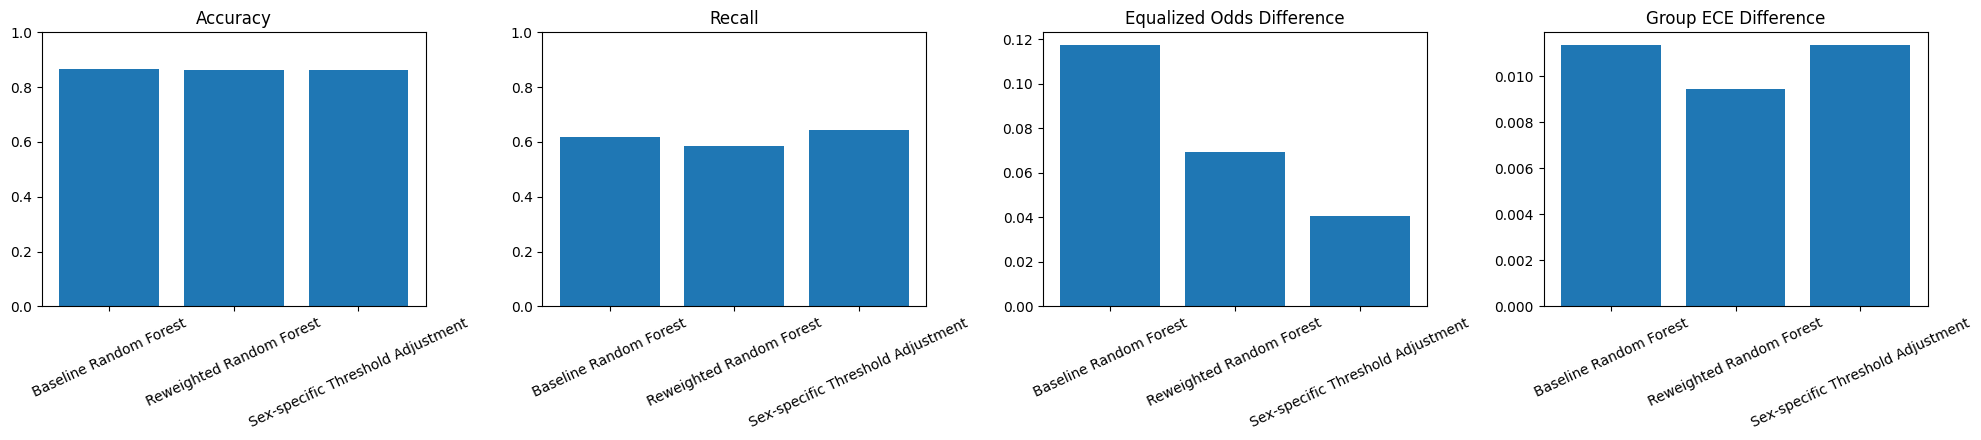

In [24]:
sex_fairness = mitigation_fairness_table.loc[
    mitigation_fairness_table["sensitive_attribute"].eq("sex")
].copy()
merged = mitigation_performance_table.merge(sex_fairness, on="method")

figure, axes = plt.subplots(1, 4, figsize=(20, 4.5))
axes[0].bar(merged["method"], merged["accuracy"])
axes[0].set_title("Accuracy")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=25)

axes[1].bar(merged["method"], merged["recall"])
axes[1].set_title("Recall")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=25)

axes[2].bar(merged["method"], merged["equalized_odds_difference"])
axes[2].set_title("Equalized Odds Difference")
axes[2].tick_params(axis="x", rotation=25)

axes[3].bar(merged["method"], merged["ece_difference"])
axes[3].set_title("Group ECE Difference")
axes[3].tick_params(axis="x", rotation=25)

figure.tight_layout()
figure.savefig(
    RESULTS_ROOT / "mitigation_tradeoffs.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()
plt.close(figure)

### Calibration and threshold-adjustment interpretation

Threshold adjustment changes binary decisions but not the underlying probability scores. Therefore, it can change decision-fairness metrics while leaving ROC-AUC, Brier score, ECE, and calibration curves unchanged. Group-specific thresholds may also be legally or ethically restricted because they use group membership at decision time.

The threshold search is performed only on the validation set. It constrains total accuracy, total recall, and per-group TPR deterioration to reduce the risk of obtaining apparent fairness merely by denying more positive outcomes to every group. The test-set `leveling_down_diagnostics.csv` must still be discussed explicitly.

Reweighing changes model training and can therefore change discrimination, ranking performance, and calibration.

## 21. Automated analytical summary

In [25]:
# ============================================================
# Descriptive final test-set audit
#
# Important:
# The rankings below are descriptive summaries of the held-out
# test-set results only.
#
# They are NOT used for:
#   - model training,
#   - threshold tuning,
#   - hyperparameter selection,
#   - mitigation-method selection,
#   - or any additional evaluation decisions.
# ============================================================

sex_comparison = mitigation_fairness_table.loc[
    mitigation_fairness_table[
        "sensitive_attribute"
    ].eq("sex")
].merge(
    mitigation_performance_table[
        [
            "method",
            "accuracy",
            "precision",
            "recall",
            "f1",
            "roc_auc",
        ]
    ],
    on="method",
)


# Method with the smallest fairness gap observed on the
# held-out test set.
#
# This is a descriptive result, not a selection step.
lowest_observed_test_fairness_gap = (
    sex_comparison
    .sort_values(
        [
            "equalized_odds_difference",
            "demographic_parity_difference",
        ],
        ascending=[
            True,
            True,
        ],
    )
    .iloc[0]
)


# Method with the highest accuracy observed on the held-out
# test set.
#
# This is also descriptive and is not used for model selection.
highest_observed_test_accuracy = (
    sex_comparison
    .sort_values(
        "accuracy",
        ascending=False,
    )
    .iloc[0]
)


baseline_test_result = (
    sex_comparison.loc[
        sex_comparison[
            "method"
        ].eq(
            "Baseline Random Forest"
        )
    ]
    .iloc[0]
)


threshold_diagnostics = (
    leveling_down_table.loc[
        leveling_down_table[
            "method"
        ].eq(
            "Sex-specific Threshold Adjustment"
        )
    ]
)


all_groups_tpr_declined = bool(
    (
        threshold_diagnostics[
            "delta_tpr"
        ]
        < 0
    ).all()
)


all_groups_positive_rate_declined = bool(
    (
        threshold_diagnostics[
            "delta_positive_prediction_rate"
        ]
        < 0
    ).all()
)


leveling_down_flag = (
    all_groups_tpr_declined
    and all_groups_positive_rate_declined
)


print(
    "AUTOMATED DESCRIPTIVE TEST-SET FINDINGS"
)

print(
    "-" * 80
)

print(
    "Important: the following comparisons are descriptive "
    "held-out test-set results. They were not used for tuning "
    "or selecting a mitigation method."
)


print(
    "\nLowest observed sex equalized-odds gap on the "
    "held-out test set:"
)

print(
    f"  Method: "
    f"{lowest_observed_test_fairness_gap['method']}"
)

print(
    f"  Equalized-odds difference: "
    f"{lowest_observed_test_fairness_gap['equalized_odds_difference']:.4f}"
)

print(
    f"  Demographic-parity difference: "
    f"{lowest_observed_test_fairness_gap['demographic_parity_difference']:.4f}"
)


print(
    "\nHighest observed accuracy on the held-out test set:"
)

print(
    f"  Method: "
    f"{highest_observed_test_accuracy['method']}"
)

print(
    f"  Accuracy: "
    f"{highest_observed_test_accuracy['accuracy']:.4f}"
)


print(
    "\nPerformance changes for the method with the lowest "
    "observed test-set equalized-odds gap relative to the "
    "baseline Random Forest:"
)

print(
    f"  Accuracy change: "
    f"{lowest_observed_test_fairness_gap['accuracy'] - baseline_test_result['accuracy']:+.4f}"
)

print(
    f"  Recall change: "
    f"{lowest_observed_test_fairness_gap['recall'] - baseline_test_result['recall']:+.4f}"
)

print(
    f"  F1 change: "
    f"{lowest_observed_test_fairness_gap['f1'] - baseline_test_result['f1']:+.4f}"
)


print(
    "\nThreshold-search mode:",
    THRESHOLD_SEARCH_METADATA[
        "search_mode"
    ],
)

print(
    "Test-set leveling-down diagnostic flag:",
    leveling_down_flag,
)


if leveling_down_flag:
    print(
        "\nWarning: TPR and positive-prediction rate declined "
        "for both sex groups. Therefore, a smaller fairness gap "
        "must be described as possible leveling down rather than "
        "as an unconditional fairness improvement."
    )

else:
    print(
        "\nThe strict leveling-down pattern was not detected "
        "on the held-out test set. Nevertheless, changes for "
        "each group must still be reported separately."
    )


print(
    "\nA mitigation method is not automatically better merely "
    "because one fairness gap decreases. It may worsen another "
    "fairness metric, calibration, recall, precision, or overall "
    "predictive utility."
)


print(
    "Sensitive-feature removal is not a complete fairness "
    "solution because proxy variables may preserve information "
    "about protected groups."
)

AUTOMATED DESCRIPTIVE TEST-SET FINDINGS
--------------------------------------------------------------------------------
Important: the following comparisons are descriptive held-out test-set results. They were not used for tuning or selecting a mitigation method.

Lowest observed sex equalized-odds gap on the held-out test set:
  Method: Sex-specific Threshold Adjustment
  Equalized-odds difference: 0.0407
  Demographic-parity difference: 0.1284

Highest observed accuracy on the held-out test set:
  Method: Baseline Random Forest
  Accuracy: 0.8669

Performance changes for the method with the lowest observed test-set equalized-odds gap relative to the baseline Random Forest:
  Accuracy change: -0.0035
  Recall change: +0.0248
  F1 change: +0.0029

Threshold-search mode: strict_anti_leveling_down
Test-set leveling-down diagnostic flag: False

The strict leveling-down pattern was not detected on the held-out test set. Nevertheless, changes for each group must still be reported separatel

## Save metadata and artifact inventory

In [26]:
metadata = {
    "seed": SEED,
    "execution_mode": EXECUTION_MODE,
    "dataset": "Adult Income (OpenML version 2)",
    "target": "income > 50K",
    "target_labels": TARGET_LABELS,
    "sensitive_attributes": SENSITIVE_ATTRIBUTES,
    "models": MODEL_NAMES,
    "model_parameters": {
        model_name: FITTED_MODELS[model_name].named_steps["model"].get_params()
        for model_name in MODEL_NAMES
    },
    "bias_mitigation_methods": [
        "Reweighing by sex and target",
        "Validation-selected sex-specific threshold adjustment",
    ],
    "selected_group_thresholds": BEST_GROUP_THRESHOLDS,
    "threshold_search_metadata": THRESHOLD_SEARCH_METADATA,
    "fairness_gap_definition": (
        "max-minus-min range across retained groups; Equalized Odds Difference is "
        "max(TPR range, FPR range)"
    ),
    "harm_score_weights": HARM_SCORE_WEIGHTS,
    "harm_score_disclaimer": (
        "Context-specific descriptive opportunity-burden score; not a standard fairness metric"
    ),
    "counterfactual_immutable_features": IMMUTABLE_FEATURES,
    "counterfactual_mutable_model_columns": MUTABLE_MODEL_COLUMNS,
    "counterfactual_education_synchronization": True,
    "minimum_intersection_size": CONFIG["minimum_intersection_size"],
    "train_size": len(X_train),
    "validation_size": len(X_validation),
    "test_size": len(X_test),
    "software_versions": {
        "python": sys.version.split()[0],
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "shap": shap.__version__,
    },
}
with open(
    RESULTS_ROOT / "experiment_metadata.json",
    "w",
    encoding="utf-8",
) as file:
    json.dump(metadata, file, indent=2, ensure_ascii=False, default=str)

# Compact tables intended to be copied directly into the report.
report_performance = performance_table.copy()
report_fairness = fairness_gap_table.copy()
report_mitigation = mitigation_performance_table.merge(
    mitigation_fairness_table.loc[
        mitigation_fairness_table["sensitive_attribute"].eq("sex")
    ],
    on="method",
    how="left",
)
report_performance.to_csv(
    RESULTS_ROOT / "REPORT_TABLE_model_performance.csv",
    index=False,
)
report_fairness.to_csv(
    RESULTS_ROOT / "REPORT_TABLE_fairness_gaps.csv",
    index=False,
)
report_mitigation.to_csv(
    RESULTS_ROOT / "REPORT_TABLE_mitigation_tradeoffs.csv",
    index=False,
)

print("Saved artifacts:")
for path in sorted(RESULTS_ROOT.rglob("*")):
    if path.is_file():
        print("-", path)

Saved artifacts:
- results_q6_corrected/REPORT_TABLE_fairness_gaps.csv
- results_q6_corrected/REPORT_TABLE_mitigation_tradeoffs.csv
- results_q6_corrected/REPORT_TABLE_model_performance.csv
- results_q6_corrected/confusion_matrices.png
- results_q6_corrected/counterfactual_explanations.csv
- results_q6_corrected/experiment_metadata.json
- results_q6_corrected/fairness_gap_summary.csv
- results_q6_corrected/intersection_group_support.csv
- results_q6_corrected/leveling_down_diagnostics.csv
- results_q6_corrected/local_shap_explanations.csv
- results_q6_corrected/local_shap_group_1_negative.png
- results_q6_corrected/local_shap_group_1_positive.png
- results_q6_corrected/local_shap_group_2_negative.png
- results_q6_corrected/local_shap_raw_feature_summary.csv
- results_q6_corrected/local_shap_verification.csv
- results_q6_corrected/logistic_regression_race_calibration.png
- results_q6_corrected/logistic_regression_race_calibration_points.csv
- results_q6_corrected/logistic_regression_rac

## References
1. Becker, B. and Kohavi, R. **Adult** dataset, UCI Machine Learning Repository; accessed through OpenML, dataset version 2.
2. Pedregosa, F. et al. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825–2830.
3. Breiman, L. (2001). *Random Forests*. Machine Learning, 45, 5–32.
4. Friedman, J. H. (2001). *Greedy Function Approximation: A Gradient Boosting Machine*. Annals of Statistics, 29(5), 1189–1232. [Partial dependence]
5. Lundberg, S. M. and Lee, S.-I. (2017). *A Unified Approach to Interpreting Model Predictions*. NeurIPS. [SHAP]
6. Kamiran, F. and Calders, T. (2012). *Data preprocessing techniques for classification without discrimination*. Knowledge and Information Systems, 33, 1–33. [Reweighing]
7. Hardt, M., Price, E., and Srebro, N. (2016). *Equality of Opportunity in Supervised Learning*. NeurIPS. [Equal Opportunity / Equalized Odds]


## Automated report-readiness validation

In [27]:
# Automated report-readiness checks
readiness_checks = {
    "full_execution_mode": EXECUTION_MODE == "full",
    "two_required_models": set(MODEL_NAMES) == {"Logistic Regression", "Random Forest"},
    "performance_rows_complete": len(performance_table) == 2,
    "sex_and_race_fairness_present": set(
        fairness_gap_table["sensitive_attribute"]
    ).issuperset({"sex", "race"}),
    "intersectional_analysis_present": "sex_x_race" in set(
        fairness_gap_table["sensitive_attribute"]
    ),
    "three_global_explanations_saved": all((RESULTS_ROOT / filename).exists() for filename in [
        "permutation_importance.png",
        "partial_dependence_plots.png",
        "shap_summary.png",
    ]),
    "three_required_local_cases": len(LOCAL_CASES) == 3,
    "local_groups_exact": (
        LOCAL_CASES[0]["actual_group"] == "Female"
        and LOCAL_CASES[1]["actual_group"] == "Female"
        and LOCAL_CASES[2]["actual_group"] == "Male"
    ),
    "local_prediction_patterns_exact": [
        case["predicted_label"] for case in LOCAL_CASES
    ] == [1, 0, 0],
    "shap_additivity_verified": maximum_difference < 1e-6,
    "all_counterfactuals_found": bool(counterfactual_table["found"].all()),
    "counterfactual_education_consistent": bool(
        counterfactual_table.loc[
            counterfactual_table["found"],
            "education_consistency_passed",
        ].all()
    ),
    "counterfactual_immutables_preserved": bool(
        counterfactual_table.loc[
            counterfactual_table["found"],
            "immutable_features_unchanged",
        ].all()
    ),
    "harm_score_retained_and_corrected": (
        "harm_score" in next(iter(HARM_RANKINGS.values())).columns
        and np.isclose(sum(HARM_SCORE_WEIGHTS.values()), 1.0)
    ),
    "two_bias_mitigation_methods": {
        "Reweighted Random Forest",
        "Sex-specific Threshold Adjustment",
    }.issubset(set(mitigation_performance_table["method"])),
    "thresholds_selected_on_validation": BEST_GROUP_THRESHOLDS is not None,
    "report_tables_saved": all((RESULTS_ROOT / filename).exists() for filename in [
        "REPORT_TABLE_model_performance.csv",
        "REPORT_TABLE_fairness_gaps.csv",
        "REPORT_TABLE_mitigation_tradeoffs.csv",
    ]),
}

readiness_table = pd.DataFrame([
    {"check": key, "passed": bool(value)}
    for key, value in readiness_checks.items()
])
readiness_table.to_csv(
    RESULTS_ROOT / "REPORT_READINESS_CHECKS.csv",
    index=False,
)
display(readiness_table)

failed_checks = readiness_table.loc[~readiness_table["passed"], "check"].tolist()
if failed_checks:
    raise RuntimeError(
        "The notebook is not yet report-ready. Failed checks: "
        + ", ".join(failed_checks)
    )

print("ALL REPORT-READINESS CHECKS PASSED.")

,check,passed
0,full_execution_mode,True
1,two_required_models,True
2,performance_rows_complete,True
3,sex_and_race_fairness_present,True
4,intersectional_analysis_present,True
5,three_global_explanations_saved,True
6,three_required_local_cases,True
7,local_groups_exact,True
8,local_prediction_patterns_exact,True
9,shap_additivity_verified,True


ALL REPORT-READINESS CHECKS PASSED.
